## Setup
This notebook runs both locally and on Kaggle. On Kaggle, turn on **Internet** in the notebook settings (needed to download the data and install `tensorboardX`). Outputs are written to `/kaggle/working/` on Kaggle and to the project folder locally.

In [15]:
%pip install -q tensorboardX imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 1.7 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [76]:
import os
import glob
import shutil
import zipfile
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import (train_test_split, StratifiedShuffleSplit)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score,
                             roc_curve,
                             accuracy_score,
                             precision_score,
                             recall_score,
                             precision_recall_curve,
                             f1_score,
                             confusion_matrix
                             )

In [17]:
warnings.filterwarnings("ignore")
RANDOM_STATE = 42

ON_KAGGLE = os.path.exists("/kaggle/input")
OUTPUT_DIR = "/kaggle/working" if ON_KAGGLE else "."
DATA_DIR = os.path.join(OUTPUT_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)

print("Running on Kaggle" if ON_KAGGLE else "Running locally")
print("Data folder:", DATA_DIR)

Running on Kaggle
Data folder: /kaggle/working/data


##### Download the BRFSS 2023 data (skipped if it is already there)
XPT_PATH = os.path.join(DATA_DIR, "LLCP2023.XPT")

if not os.path.exists(XPT_PATH):
    !wget -O LLCP2023XPT.zip https://www.cdc.gov/brfss/annual_data/2023/files/LLCP2023XPT.zip
    !unzip -o LLCP2023XPT.zip -d {DATA_DIR}
    !mv "{DATA_DIR}/LLCP2023.XPT " {XPT_PATH}
    !rm LLCP2023XPT.zip

print("Using:", XPT_PATH)


In [18]:
df = pd.read_sas(XPT_PATH, format="xport", encoding="latin-1")
df.head()

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,DROCDY4_,_RFBING6,_DRNKWK2,_RFDRHV8,_FLSHOT7,_PNEUMO3,_AIDTST4,_RFSEAT2,_RFSEAT3,_DRNKDRV
0,1.0,1.0,03012023,03,01,2023,1100.0,2023000001,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,2.0,2.0,2.0,1.0,1.0,9.0
1,1.0,1.0,01062023,01,06,2023,1100.0,2023000002,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
2,1.0,1.0,03082023,03,08,2023,1100.0,2023000003,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
3,1.0,1.0,03062023,03,06,2023,1100.0,2023000004,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,1.0,1.0,1.0,9.0
4,1.0,1.0,01062023,01,06,2023,1100.0,2023000005,2.023000e+09,1.0,...,7.000000e+00,1.0,4.700000e+01,1.0,2.0,1.0,2.0,1.0,1.0,2.0


In [21]:
target = "DIABETE4"

binary_cols = ["_RFHYPE6", "_RFCHOL3", "CVDSTRK3", "_MICHD", "CHCKDNY2",
               "_TOTINDA", "_RFDRHV8", "_HLTHPL1", "MEDCOST1", "DIFFWALK", "_SEX"]
ordinal_cols = ["GENHLTH", "_AGEG5YR", "_EDUCAG", "_INCOMG1", "_SMOKER3", "_CHOLCH3"]
numeric_cols = ["_BMI5", "PHYSHLTH", "MENTHLTH", "_DRNKWK2", "DROCDY4_",
                "_AGE80", "HTIN4", "WTKG3", "PA3MIN_", "PA3VIGM_", "STRFREQ_"]

In [22]:
diabete_study = df[numeric_cols + ordinal_cols + binary_cols + [target]]
diabete_study.to_csv(os.path.join(DATA_DIR, "BRFSS_dataset.csv"), index=False)

In [23]:
data = pd.read_csv(os.path.join(DATA_DIR, "BRFSS_dataset.csv"))
data.shape

(433323, 29)

In [24]:
data.columns

Index(['_BMI5', 'PHYSHLTH', 'MENTHLTH', '_DRNKWK2', 'DROCDY4_', '_AGE80',
       'HTIN4', 'WTKG3', 'PA3MIN_', 'PA3VIGM_', 'STRFREQ_', 'GENHLTH',
       '_AGEG5YR', '_EDUCAG', '_INCOMG1', '_SMOKER3', '_CHOLCH3', '_RFHYPE6',
       '_RFCHOL3', 'CVDSTRK3', '_MICHD', 'CHCKDNY2', '_TOTINDA', '_RFDRHV8',
       '_HLTHPL1', 'MEDCOST1', 'DIFFWALK', '_SEX', 'DIABETE4'],
      dtype='object')

In [25]:
# rename columns from code to variable names
column_names = {
    # Target
    "DIABETE4": "diabetes",

    # Binary
    "_RFHYPE6": "high_blood_pressure",
    "_RFCHOL3": "high_cholesterol",
    "CVDSTRK3": "stroke",
    "_MICHD":   "heart_disease",
    "CHCKDNY2": "kidney_disease",
    "_TOTINDA": "physical_activity",
    "_RFDRHV8": "heavy_drinker",
    "_HLTHPL1": "health_insurance",
    "MEDCOST1": "cant_afford_doctor",
    "DIFFWALK": "difficulty_walking",
    "_SEX":     "sex",

    # Ordinal
    "GENHLTH":  "general_health",
    "_AGEG5YR": "age_group",
    "_EDUCAG":  "education",
    "_INCOMG1": "income",
    "_SMOKER3": "smoking_status",
    "_CHOLCH3": "cholesterol_check",

    # Numeric
    "_BMI5":    "bmi",
    "PHYSHLTH": "poor_physical_health_days",
    "MENTHLTH": "poor_mental_health_days",
    "_DRNKWK2": "drinks_per_week",
    "DROCDY4_": "drink_occasions_per_day",
    "_AGE80":   "age",
    "HTIN4":    "height_inches",
    "WTKG3":     "weight_kg",
    "PA3MIN_":  "exercise_minutes_per_week",
    "PA3VIGM_": "vigorous_exercise_minutes_per_week",
    "STRFREQ_": "strength_training_per_week",
}

data_renamed = data.rename(columns=column_names)


In [26]:
num = data_renamed.select_dtypes("number").columns
data_renamed[num] = data_renamed[num].mask(data_renamed[num].abs() < 1e-10, 0)

In [27]:
data_renamed.head()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
0,3047.0,88.0,88.0,0.0,0.0,80.0,63.0,7802.0,NaN,NaN,...,2.0,2.0,2.0,2.0,1.0,1.0,2.0,1.0,2.0,1.0
1,2856.0,88.0,88.0,0.0,0.0,80.0,57.0,5987.0,360.0,180.0,...,2.0,2.0,2.0,1.0,1.0,1.0,2.0,2.0,2.0,3.0
2,2231.0,6.0,2.0,0.0,0.0,80.0,64.0,5897.0,36.0,18.0,...,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,3.0
3,2744.0,2.0,88.0,0.0,0.0,78.0,66.0,7711.0,180.0,90.0,...,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,3.0
4,2585.0,88.0,88.0,47.0,7.0,76.0,68.0,7711.0,600.0,90.0,...,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,1.0


## Basic Data Explaratory and handling missing values
The BRFSS survey is an encoded survey where numbers 7 and 9 mean respectfully don't know or refused to provide. In this study, we will consider it as NaN value. Let's first check how many of them are there per columns. These two codes are included in following features: **["diabetes", "stroke", "kidney_disease", "cant_afford_doctor", "difficulty_walking", "general_health"]**
Reference source: **codebook23_llcp-v2-508**

In [28]:
## check for missingness
dk_cols = ["diabetes", "stroke", "kidney_disease", "cant_afford_doctor",
           "difficulty_walking", "general_health", "difficulty_walking",
           "high_cholesterol"]

missing_table = pd.DataFrame({
    "7 appearance in %":     (data_renamed[dk_cols] == 7).mean() * 100,
    "9 appearance in %":     (data_renamed[dk_cols] == 9).mean() * 100,
    "7 & 9 appearance in %": data_renamed[dk_cols].isin([7, 9]).mean() * 100,
}).round(2)
missing_table.index.name = "column_name"

missing_table


,7 appearance in %,9 appearance in %,7 & 9 appearance in %
column_name,,,
diabetes,0.16,0.07,0.23
stroke,0.28,0.06,0.34
kidney_disease,0.37,0.06,0.44
cant_afford_doctor,0.27,0.08,0.35
difficulty_walking,0.28,0.11,0.39
general_health,0.21,0.08,0.29
difficulty_walking,0.28,0.11,0.39
high_cholesterol,0.00,0.76,0.76


In [29]:
## check for NAN
columns = ["exercise_minutes_per_week",
           "vigorous_exercise_minutes_per_week",
           "high_cholesterol","bmi","weight_kg",
           "height_inches","strength_training_per_week",
           "heart_disease"

           ]

In [30]:
# Codes that mean "don't know / refused / missing" in each column
missing_codes = {
    "diabetes":                   [7, 9],
    "stroke":                     [7, 9],
    "kidney_disease":             [7, 9],
    "cant_afford_doctor":         [7, 9],
    "difficulty_walking":         [7, 9],
    "general_health":             [7, 9],
    "high_blood_pressure":        [9],
    "high_cholesterol":           [9],
    "physical_activity":          [9],
    "heavy_drinker":              [9],
    "health_insurance":           [9],
    "education":                  [9],
    "income":                     [9],
    "smoking_status":             [9],
    "cholesterol_check":          [9],
    "poor_physical_health_days":  [77, 99],
    "poor_mental_health_days":    [77, 99],
    "age_group":                  [14],
    "drinks_per_week":            [99900],
    "drink_occasions_per_day":    [900],
    "strength_training_per_week": [99000],
}

all_codes = [7, 9, 77, 99, 14, 99900, 900, 99000]

rows = {}
for col, codes in missing_codes.items():
    s = data_renamed[col]
    row = {f"{c} appearance in %": (s == c).mean() * 100 if c in codes else np.nan
           for c in all_codes}
    row["NaN in %"] = s.isna().mean() * 100
    row["total missing in %"] = (s.isin(codes) | s.isna()).mean() * 100
    rows[col] = row

missing_table = pd.DataFrame(rows).T.round(2)
missing_table.index.name = "column_name"

missing_table.sort_values("total missing in %", ascending=False)


,7 appearance in %,9 appearance in %,77 appearance in %,99 appearance in %,14 appearance in %,99900 appearance in %,900 appearance in %,99000 appearance in %,NaN in %,total missing in %
column_name,,,,,,,,,,
income,NaN,19.99,NaN,NaN,NaN,NaN,NaN,NaN,0.00,19.99
high_cholesterol,NaN,0.76,NaN,NaN,NaN,NaN,NaN,NaN,11.96,12.71
heavy_drinker,NaN,7.58,NaN,NaN,NaN,NaN,NaN,NaN,0.00,7.58
drinks_per_week,NaN,NaN,NaN,NaN,NaN,7.58,NaN,NaN,0.00,7.58
drink_occasions_per_day,NaN,NaN,NaN,NaN,NaN,NaN,6.91,NaN,0.00,6.91
cholesterol_check,NaN,6.10,NaN,NaN,NaN,NaN,NaN,NaN,0.00,6.10
smoking_status,NaN,5.32,NaN,NaN,NaN,NaN,NaN,NaN,0.00,5.32
health_insurance,NaN,4.31,NaN,NaN,NaN,NaN,NaN,NaN,0.00,4.31
difficulty_walking,0.28,0.11,NaN,NaN,NaN,NaN,NaN,NaN,3.73,4.12


Drop 7 and 9 inside the target (7=don't know, 9=refused)

In [31]:
# Drop rows where the target is unknown (7 = don't know, 9 = refused) or blank
clean_data = data_renamed[~data_renamed["diabetes"].isin([7, 9])]
clean_data = clean_data.dropna(subset=["diabetes"])

print(f"{len(data_renamed)} rows before 'vs', {len(clean_data)} rows now")
clean_data["diabetes"].value_counts()


433323 rows before 'vs', 432339 rows now


diabetes
3.0    358706
1.0     59786
4.0     10594
2.0      3253
Name: count, dtype: int64


**According to Vounzoulaki in his research report titled "Progression to type 2 diabetes in women with a known history of gestational diabetes: systematic review and meta-analysis", women with a known history of gestational diabetes (diabetes during pregnancy) were 10 times more likely to develop type 2 diabetes (Vounzoulaki et al., 2020). For this reason, we will merge data on diabetes in pregnant women with prediabetes data.******


In [32]:
# Gestational diabetes only (2), at risk, together with prediabetes (4)
clean_data["diabetes"] = clean_data["diabetes"].replace({2: 4})
clean_data["diabetes"].value_counts()

diabetes
3.0    358706
1.0     59786
4.0     13847
Name: count, dtype: int64

In [33]:
## replace 7 (don't know) with NaN
columns = ["difficulty_walking", "kidney_disease", "cant_afford_doctor",
           "stroke", "general_health"]
clean_data[columns].head()

,difficulty_walking,kidney_disease,cant_afford_doctor,stroke,general_health
0,1.0,2.0,2.0,2.0,2.0
1,2.0,2.0,2.0,2.0,2.0
2,1.0,2.0,1.0,2.0,4.0
3,1.0,2.0,2.0,2.0,2.0
4,1.0,2.0,2.0,2.0,4.0


In [36]:
###### Codes that mean "don't know / refused / missing" in each column
to_nan = {
    "stroke":                     [7, 9],
    "kidney_disease":             [7, 9],
    "cant_afford_doctor":         [7, 9],
    "difficulty_walking":         [7, 9],
    "general_health":             [7, 9],
    "high_blood_pressure":        [9],
    "physical_activity":          [9],
    "heavy_drinker":              [9],
    "health_insurance":           [9],
    "education":                  [9],
    "smoking_status":             [9],
    "cholesterol_check":          [9],
    "poor_physical_health_days":  [77, 99],
    "poor_mental_health_days":    [77, 99],
    "age_group":                  [14],
    "drinks_per_week":            [99900],
    "drink_occasions_per_day":    [900],
    "strength_training_per_week": [99000],
}

clean_data = clean_data.replace({col: {code: np.nan for code in codes}
                                 for col, codes in to_nan.items()})


In [37]:
for col in ["poor_physical_health_days", "poor_mental_health_days"]:
    clean_data[col] = clean_data[col].replace(88, 0)

In [39]:
# check for missing values
print("Missing values...")
(clean_data.isna().mean() * 100).round(2).sort_values(ascending=False)

Missing values...


exercise_minutes_per_week             28.38
vigorous_exercise_minutes_per_week    27.34
high_cholesterol                      11.91
bmi                                    9.30
weight_kg                              7.83
heavy_drinker                          7.54
drinks_per_week                        7.54
drink_occasions_per_day                6.88
height_inches                          6.42
cholesterol_check                      6.06
smoking_status                         5.29
health_insurance                       4.27
difficulty_walking                     4.09
strength_training_per_week             3.29
poor_physical_health_days              2.47
poor_mental_health_days                1.85
age_group                              1.75
heart_disease                          1.00
education                              0.51
high_blood_pressure                    0.40
kidney_disease                         0.37
cant_afford_doctor                     0.34
general_health                  

In [41]:
clean_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 432339 entries, 0 to 433322
Data columns (total 29 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   bmi                                 392119 non-null  float64
 1   poor_physical_health_days           421667 non-null  float64
 2   poor_mental_health_days             424355 non-null  float64
 3   drinks_per_week                     399739 non-null  float64
 4   drink_occasions_per_day             402612 non-null  float64
 5   age                                 432339 non-null  float64
 6   height_inches                       404602 non-null  float64
 7   weight_kg                           398482 non-null  float64
 8   exercise_minutes_per_week           309628 non-null  float64
 9   vigorous_exercise_minutes_per_week  314131 non-null  float64
 10  strength_training_per_week          418108 non-null  float64
 11  general_health                 

In [42]:
clean_data.describe()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
count,392119.000000,421667.000000,424355.000000,399739.000000,402612.000000,432339.000000,404602.000000,398482.000000,309628.000000,314131.000000,...,431119.000000,428022.000000,430728.000000,431143.000000,399739.000000,413881.000000,430870.000000,414666.000000,432339.000000,432339.000000
mean,2847.766461,4.478899,4.355040,280.333270,16.430516,55.379346,67.066945,8288.308315,636.715375,162.025047,...,1.957555,1.915378,1.952367,1.247115,1.059249,1.054591,1.914125,1.838916,1.529837,2.755458
std,653.954620,8.823183,8.316287,815.396316,27.138132,17.909326,4.185244,2133.152545,1323.048113,536.396921,...,0.201603,0.278318,0.212989,0.431335,0.236090,0.227180,0.280180,0.367609,0.499110,0.724823
min,1202.000000,0.000000,0.000000,0.000000,0.000000,18.000000,36.000000,2268.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2410.000000,0.000000,0.000000,0.000000,0.000000,41.000000,64.000000,6804.000000,140.000000,0.000000,...,2.000000,2.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,1.000000,3.000000
50%,2740.000000,0.000000,0.000000,23.000000,3.000000,58.000000,67.000000,8029.000000,315.000000,0.000000,...,2.000000,2.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,3.000000
75%,3162.000000,4.000000,5.000000,233.000000,17.000000,71.000000,70.000000,9435.000000,672.000000,144.500000,...,2.000000,2.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,3.000000
max,9984.000000,30.000000,30.000000,53200.000000,100.000000,80.000000,95.000000,28400.000000,118602.000000,59301.000000,...,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,4.000000


In [43]:
TARGET = "diabetes"
features = [
    # Numeric
    "bmi", "poor_physical_health_days", "poor_mental_health_days",
    "drinks_per_week", "drink_occasions_per_day", "age",
    "height_inches", "weight_kg", "exercise_minutes_per_week",
    "vigorous_exercise_minutes_per_week", "strength_training_per_week",

    # Ordinal
    "general_health", "age_group", "education", "income",
    "smoking_status", "cholesterol_check",

    # Binary
    "high_blood_pressure", "high_cholesterol", "stroke", "heart_disease",
    "kidney_disease", "physical_activity", "heavy_drinker",
    "health_insurance", "cant_afford_doctor", "difficulty_walking", "sex",
]

Features/target

## Encode Binaries values
for sex, 0 is male and 1 is female

In [44]:
# 1 i yes, 2 is no
one_is_yes = ["stroke", "heart_disease", "kidney_disease", "cant_afford_doctor",
              "difficulty_walking", "physical_activity", "health_insurance"]

# 1 is no, 2 is yes
one_is_no = ["high_blood_pressure", "high_cholesterol", "heavy_drinker"]


In [46]:
for col in one_is_yes:
    clean_data[col] = clean_data[col].map({1: 1, 2: 0})

for col in one_is_no:
    clean_data[col] = clean_data[col].map({1: 0, 2: 1})

clean_data["sex"] = clean_data["sex"].map({1: 0, 2: 1})

# high_cholesterol: keep "unknown" (never checked / don't know) as its own category
clean_data["high_cholesterol"] = clean_data["high_cholesterol"].fillna(-1)   # -1 = unknown


## Encode ordinal values

In [47]:
# smoking: 0 = never, 1 = former, 2 = some days, 3 = daily
clean_data["smoking_status"] = clean_data["smoking_status"].map({4: 0, 3: 1, 2: 2, 1: 3})

# cholesterol check: 0 = within 5 years, 1 = more than 5 years ago, 2 = never
clean_data["cholesterol_check"] = clean_data["cholesterol_check"].map({1: 0, 2: 1, 3: 2})

# income: keep 1–7, unknown (9) becomes 0
clean_data["income"] = clean_data["income"].replace(9, 0)

# age group: 0 = 18–24, 1 = 25–29, ..., 12 = 80+
clean_data["age_group"] = clean_data["age_group"] - 1


BRFSS for privacy reasons multiplied some numerical values to 100 or 1000. This section will bring those features to their initial values

In [48]:
scale_map = {
    "bmi": 100,
    "weight_kg": 100,
    "drinks_per_week": 100,
    "drink_occasions_per_day": 100,
    "strength_training_per_week": 1000,
}
for col, factor in scale_map.items():
    clean_data[col] = clean_data[col] / factor
print("Complete")

Complete


In [49]:
clean_data.head()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
0,30.47,0.0,0.0,0.00,0.00,80.0,63.0,78.02,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.0,NaN,1.0,0.0,1.0
1,28.56,0.0,0.0,0.00,0.00,80.0,57.0,59.87,360.0,180.0,...,NaN,NaN,NaN,1.0,NaN,1.0,NaN,NaN,0.0,3.0
2,22.31,6.0,2.0,0.00,0.00,80.0,64.0,58.97,36.0,18.0,...,NaN,NaN,NaN,1.0,NaN,1.0,1.0,1.0,0.0,3.0
3,27.44,2.0,0.0,0.00,0.00,78.0,66.0,77.11,180.0,90.0,...,NaN,NaN,NaN,1.0,NaN,1.0,NaN,1.0,0.0,3.0
4,25.85,0.0,0.0,0.47,0.07,76.0,68.0,77.11,600.0,90.0,...,NaN,NaN,NaN,1.0,NaN,1.0,NaN,1.0,0.0,1.0


In [50]:
clean_data["high_cholesterol"].value_counts()

high_cholesterol
-1.0    273692
 0.0    158647
Name: count, dtype: int64

## Check for outlier

In [51]:
clean_data.describe()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
count,392119.000000,421667.000000,424355.000000,399739.000000,402612.000000,432339.000000,404602.000000,398482.000000,309628.000000,314131.000000,...,18299.0,36220.0,20517.0,324601.0,23684.0,391287.0,37001.0,66796.0,229069.0,432339.000000
mean,28.477665,4.478899,4.355040,2.803333,0.164305,55.379346,67.066945,82.883083,636.715375,162.025047,...,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,2.755458
std,6.539546,8.823183,8.316287,8.153963,0.271381,17.909326,4.185244,21.331525,1323.048113,536.396921,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.724823
min,12.020000,0.000000,0.000000,0.000000,0.000000,18.000000,36.000000,22.680000,0.000000,0.000000,...,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,1.000000
25%,24.100000,0.000000,0.000000,0.000000,0.000000,41.000000,64.000000,68.040000,140.000000,0.000000,...,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,3.000000
50%,27.400000,0.000000,0.000000,0.230000,0.030000,58.000000,67.000000,80.290000,315.000000,0.000000,...,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,3.000000
75%,31.620000,4.000000,5.000000,2.330000,0.170000,71.000000,70.000000,94.350000,672.000000,144.500000,...,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,3.000000
max,99.840000,30.000000,30.000000,532.000000,1.000000,80.000000,95.000000,284.000000,118602.000000,59301.000000,...,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,4.000000


drinks_per_week shows a surprising maximun value of 532 drinks in a week, which is in average around 76 drinks per day.

In [52]:
# check the distribution of drinks_per_week
clean_data["drinks_per_week"].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999, 0.99999, 1.0])


0.25000      0.000000
0.50000      0.230000
0.75000      2.330000
0.90000      8.000000
0.95000     14.000000
0.99000     30.000000
0.99900     84.000000
0.99990    224.244446
0.99999    511.036680
1.00000    532.000000
Name: drinks_per_week, dtype: float64

At 99.9% quantile, only 84 drinks were taken in a week, which is 12 drinks per day.  At 99.99%, it is 224 drinks per week, around 32 drinks per day. According to the Ohio State report, a clinical sample of people with alcohol use disorder averaged 6.4 drinks per day. My personal assumption is that values in the extreme outliers might be due to a typing error. The value will be capped at 0.999 quantile

In [53]:
cap = clean_data["drinks_per_week"].quantile(0.999)
clean_data["drinks_per_week"] = clean_data["drinks_per_week"].clip(upper=cap)


**exercise_minutes_per_week and vigorous_exercise_minutes_per_week also have an issue. Their maximun values are 118602 and 59301 minutes while a week has 24*60*7 minutes = 10080 minutes**

In [54]:
check_activity_min = clean_data["exercise_minutes_per_week"].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999, 0.99999, 1.0])
hourly_check_weekly = {
    "quantile %": check_activity_min.index * 100,
    "minutes": check_activity_min,
    "hours":check_activity_min/60
    }
pd.DataFrame(hourly_check_weekly)

,quantile %,minutes,hours
0.25000,25.000,140.0000,2.333333
0.50000,50.000,315.0000,5.250000
0.75000,75.000,672.0000,11.200000
0.90000,90.000,1440.0000,24.000000
0.95000,95.000,2310.0000,38.500000
0.99000,99.000,4872.0000,81.200000
0.99900,99.900,13244.7600,220.746000
0.99990,99.990,47522.2380,792.037300
0.99999,99.999,94416.1704,1573.602840
1.00000,100.000,118602.0000,1976.700000


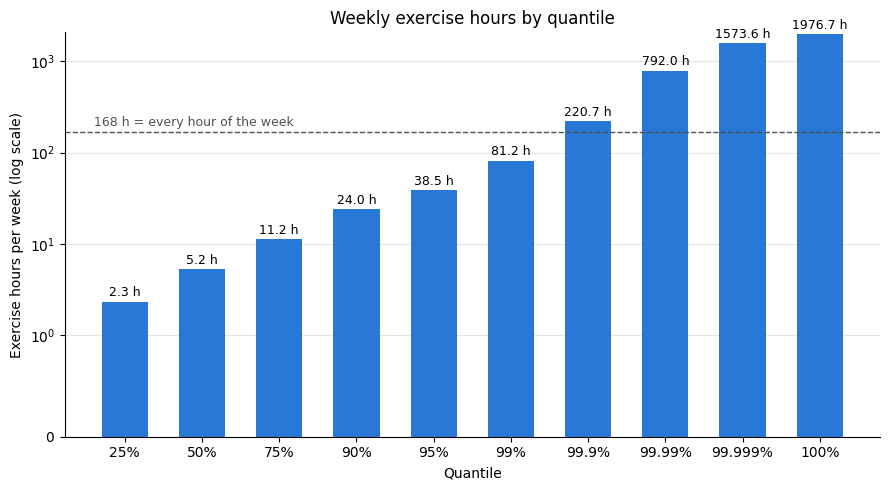

In [55]:
import matplotlib.pyplot as plt
hourly_df = pd.DataFrame(hourly_check_weekly)

fig, ax = plt.subplots(figsize=(9, 5))
labels = [f"{q:g}%" for q in hourly_df["quantile %"]]
bars = ax.bar(labels, hourly_df["hours"], color="#2a78d6", width=0.6)

# Value on top of each bar
for bar, h in zip(bars, hourly_df["hours"]):
    ax.annotate(f"{h:.1f} h", (bar.get_x() + bar.get_width() / 2, h),
                textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)

# A week has 168 hours: anything above this line is impossible
ax.axhline(168, color="#52514e", linewidth=1, linestyle="--")
ax.text(-0.4, 168 * 1.15, "168 h = every hour of the week", color="#52514e", fontsize=9)

ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("Quantile")
ax.set_ylabel("Exercise hours per week (log scale)")
ax.set_title("Weekly exercise hours by quantile")
ax.grid(axis="y", color="#e5e5e3", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


Considering that a week has 168h (24h per day), any practice value beyond 168h is mathematically impossible. At 99%, a consistent practice time of 81.2h per week (11h per day) seems also to be quite impossible even for profesionnal athletes. The most plausible value is found at 95% quantile (38.5h)

In [56]:
cap = clean_data["exercise_minutes_per_week"].quantile(0.95)
clean_data["exercise_minutes_per_week"] = clean_data["exercise_minutes_per_week"].clip(upper=cap)

Check for vigorous_exercise_minutes_per_week

In [57]:
check_activity_min = clean_data["vigorous_exercise_minutes_per_week"].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999, 0.99999, 1.0])
hourly_check_weekly = {
    "quantile %": check_activity_min.index * 100,
    "minutes": check_activity_min,
    "hours":check_activity_min/60
    }
pd.DataFrame(hourly_check_weekly)

,quantile %,minutes,hours
0.25000,25.000,0.000,0.000000
0.50000,50.000,0.000,0.000000
0.75000,75.000,144.500,2.408333
0.90000,90.000,420.000,7.000000
0.95000,95.000,780.000,13.000000
0.99000,99.000,2100.000,35.000000
0.99900,99.900,4620.000,77.000000
0.99990,99.990,16051.320,267.522000
0.99999,99.999,43364.376,722.739600
1.00000,100.000,59301.000,988.350000


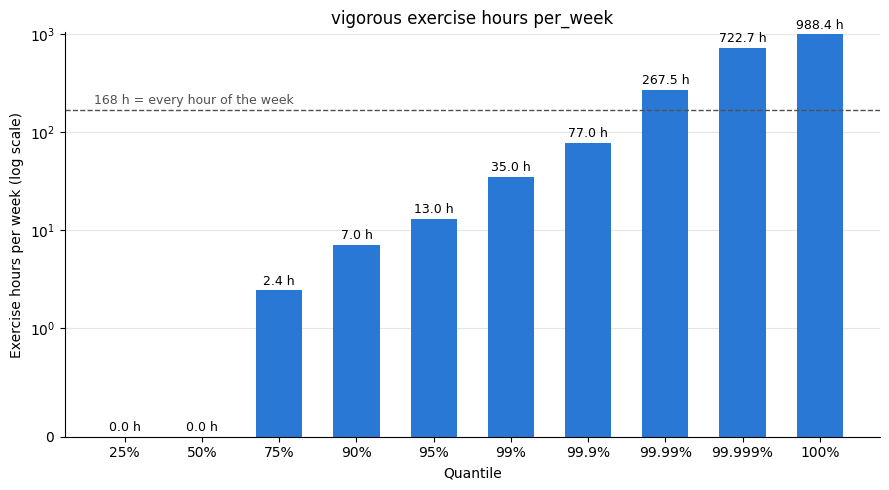

In [59]:
hourly_df = pd.DataFrame(hourly_check_weekly)

fig, ax = plt.subplots(figsize=(9, 5))
labels = [f"{q:g}%" for q in hourly_df["quantile %"]]
bars = ax.bar(labels, hourly_df["hours"], color="#2a78d6", width=0.6)

# Value on top of each bar
for bar, h in zip(bars, hourly_df["hours"]):
    ax.annotate(f"{h:.1f} h", (bar.get_x() + bar.get_width() / 2, h),
                textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)

# A week has 168 hours: anything above this line is impossible
ax.axhline(168, color="#52514e", linewidth=1, linestyle="--")
ax.text(-0.4, 168 * 1.15, "168 h = every hour of the week", color="#52514e", fontsize=9)

ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("Quantile")
ax.set_ylabel("Exercise hours per week (log scale)")
ax.set_title("vigorous exercise hours per_week")
ax.grid(axis="y", color="#e5e5e3", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


In [60]:
cap = clean_data["vigorous_exercise_minutes_per_week"].quantile(0.95)
clean_data["vigorous_exercise_minutes_per_week"] = clean_data["vigorous_exercise_minutes_per_week"].clip(upper=cap)

People who answered "no physical activity" (`physical_activity = 0`) were not asked how long they exercise, so BRFSS left their exercise minutes blank. Their real value is 0 minutes. The caps above were computed on active people only, before filling these zeros.

In [61]:
inactive = clean_data["physical_activity"] == 0
clean_data.loc[inactive, ["exercise_minutes_per_week", "vigorous_exercise_minutes_per_week"]] = 0

clean_data[["exercise_minutes_per_week", "vigorous_exercise_minutes_per_week"]].isna().mean() * 100

exercise_minutes_per_week             28.383051
vigorous_exercise_minutes_per_week    27.341507
dtype: float64

In [62]:
numeric_cols = ["bmi", "age", "height_inches", "weight_kg",
                "poor_physical_health_days", "poor_mental_health_days",
                "drinks_per_week", "drink_occasions_per_day",
                "exercise_minutes_per_week", "vigorous_exercise_minutes_per_week",
                "strength_training_per_week"]

clean_data[numeric_cols].describe()

,bmi,age,height_inches,weight_kg,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,strength_training_per_week
count,392119.000000,432339.000000,404602.000000,398482.000000,421667.000000,424355.000000,399739.000000,402612.000000,309628.000000,314131.000000,418108.000000
mean,28.477665,55.379346,67.066945,82.883083,4.478899,4.355040,2.738830,0.164305,539.627020,118.849458,1.863999
std,6.539546,17.909326,4.185244,21.331525,8.823183,8.316287,6.682283,0.271381,596.439761,212.596378,2.844207
min,12.020000,18.000000,36.000000,22.680000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.100000,41.000000,64.000000,68.040000,0.000000,0.000000,0.000000,0.000000,140.000000,0.000000,0.000000
50%,27.400000,58.000000,67.000000,80.290000,0.000000,0.000000,0.230000,0.030000,315.000000,0.000000,0.467000
75%,31.620000,71.000000,70.000000,94.350000,4.000000,5.000000,2.330000,0.170000,672.000000,144.500000,3.000000
max,99.840000,80.000000,95.000000,284.000000,30.000000,30.000000,84.000000,1.000000,2310.000000,780.000000,97.000000


Similar with exercise per week, any value above the total number of hours per week (168h) is impossible and 11h constant exercise is not very plausible. We will also cap at 95% quantille.

At 99%, it is recorded at 4872 min, which is equivalent to 81.2h per week, 

In [63]:
X = clean_data[features]
Y = clean_data[TARGET]

Check for class Imbalance

In [64]:
classes = Y.value_counts()
target_class_imbalance = pd.DataFrame({
    "class": classes.index,
    "class_percentage %": (classes * 100 / len(Y)).round(2),
}).reset_index(drop=True)
target_class_imbalance

,class,class_percentage %
0,3.0,82.97
1,1.0,13.83
2,4.0,3.20


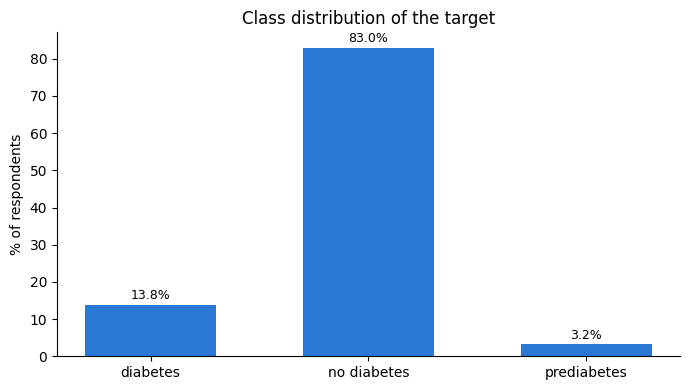

In [65]:
classes = Y.value_counts().sort_index()
target_class_imbalance = pd.DataFrame({
    "class": classes.index.astype(int).astype(str),
    "class_percentage": (classes / len(Y) * 100).round(2).values,
})

class_names = {"1": "diabetes", "2": "pregnancy only", "3": "no diabetes", "4": "prediabetes"}
labels = target_class_imbalance["class"].map(class_names)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, target_class_imbalance["class_percentage"], color="#2a78d6", width=0.6)
for bar, p in zip(bars, target_class_imbalance["class_percentage"]):
    ax.annotate(f"{p:.1f}%", (bar.get_x() + bar.get_width() / 2, p),
                textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)
ax.set_ylabel("% of respondents")
ax.set_title("Class distribution of the target")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


In [66]:
import os
from datetime import datetime
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (roc_auc_score,
                             roc_curve,
                             accuracy_score,
                             balanced_accuracy_score,
                             precision_score,
                             recall_score,
                             precision_recall_curve,
                             average_precision_score,
                             f1_score,
                             fbeta_score,
                             make_scorer,
                             confusion_matrix,
                             classification_report)
from tensorboardX import SummaryWriter

RANDOM_STATE = 42
LOG_DIR = os.path.join(OUTPUT_DIR, "runs")   # view with: tensorboard --logdir runs
# 2 (diabetes only during pregnancy) was merged into 4 -> "at risk"
CLASS_NAMES = {1: "diabetes", 3: "no diabetes", 4: "at risk"}
CLASS_COLORS = {1: "#2a78d6", 3: "#1baf7a", 4: "#eda100"}   # one fixed color per class
FLAG_CLASSES = [1, 4]   # diabetes or at risk -> flagged for follow-up
results_log = []   # every experiment's summary lands here -> becomes your results table


# ---------- Screening = binary view: needs follow-up (diabetes or at risk) vs no diabetes ----------
def is_flagged(class_labels):
    return np.isin(np.asarray(class_labels), FLAG_CLASSES)

def screen_sensitivity(y_true, y_pred):
    return recall_score(is_flagged(y_true), is_flagged(y_pred), zero_division=0)

def screen_precision(y_true, y_pred):
    return precision_score(is_flagged(y_true), is_flagged(y_pred), zero_division=0)

def screen_specificity(y_true, y_pred):
    actually_flagged = is_flagged(y_true)
    predicted_flagged = is_flagged(y_pred)
    return (~predicted_flagged[~actually_flagged]).mean()

def screen_f1(y_true, y_pred):
    return f1_score(is_flagged(y_true), is_flagged(y_pred), zero_division=0)

def screen_f2(y_true, y_pred):
    return fbeta_score(is_flagged(y_true), is_flagged(y_pred), beta=2, zero_division=0)


def log_experiment(run_name, pipeline, config, X_train, y_train, X_val, y_val,
                   do_cv=True, use_tensorboard=True):
    '''
    Fits `pipeline`, evaluates it on the validation set, logs to TensorBoard,
    and records a row for the results table. Returns the fitted pipeline.

    run_name : short descriptive string, e.g. "logreg_balanced"
    config   : dict of whatever you want tracked, e.g. {"model": "LogisticRegression", "C": 1.0}
    '''
    pipeline.fit(X_train, y_train)
    classes = pipeline.classes_
    labels = [CLASS_NAMES.get(int(class_code), str(class_code)) for class_code in classes]

    val_probs = pipeline.predict_proba(X_val)
    val_preds = pipeline.predict(X_val)
    y_val_array = np.asarray(y_val)
    y_val_binarized = label_binarize(y_val_array, classes=classes)

    # ---------- 1. Main metrics: screening (diabetes or at risk = flagged) ----------
    flagged = is_flagged(val_preds)
    metrics = {
        "screen_sensitivity": screen_sensitivity(y_val_array, val_preds),
        "screen_precision": screen_precision(y_val_array, val_preds),
        "screen_f2": screen_f2(y_val_array, val_preds),
        "screen_f1": screen_f1(y_val_array, val_preds),
    }

    # ---------- 2. Per-group metrics ----------
    metrics["screen_specificity"] = screen_specificity(y_val_array, val_preds)
    metrics["pct_flagged"] = flagged.mean() * 100
    metrics["missed/diabetes"] = (val_preds[y_val_array == 1] == 3).mean()   # diabetes predicted as no diabetes
    for flag_class in FLAG_CLASSES:
        metrics[f"screen_sensitivity/{CLASS_NAMES[flag_class]}"] = flagged[y_val_array == flag_class].mean()

    per_class_precision = precision_score(y_val_array, val_preds, average=None, labels=classes, zero_division=0)
    per_class_recall = recall_score(y_val_array, val_preds, average=None, labels=classes, zero_division=0)
    per_class_f1 = f1_score(y_val_array, val_preds, average=None, labels=classes, zero_division=0)
    for class_index, class_name in enumerate(labels):
        class_is_true = y_val_binarized[:, class_index]
        class_probability = val_probs[:, class_index]
        metrics[f"val_precision/{class_name}"] = per_class_precision[class_index]
        metrics[f"val_recall/{class_name}"] = per_class_recall[class_index]   # = sensitivity for that class
        metrics[f"val_f1/{class_name}"] = per_class_f1[class_index]
        metrics[f"val_roc_auc/{class_name}"] = roc_auc_score(class_is_true, class_probability)
        metrics[f"val_pr_auc/{class_name}"] = average_precision_score(class_is_true, class_probability)

    # ---------- 3. Supporting metrics: overall model quality ----------
    metrics.update({
        "val_roc_auc_ovr": roc_auc_score(y_val_array, val_probs, multi_class="ovr", average="macro"),
        "val_f1_macro": f1_score(y_val_array, val_preds, average="macro", zero_division=0),
        "val_balanced_accuracy": balanced_accuracy_score(y_val_array, val_preds),
        "val_accuracy": accuracy_score(y_val_array, val_preds),
        "val_precision_macro": precision_score(y_val_array, val_preds, average="macro", zero_division=0),
        "val_recall_macro": recall_score(y_val_array, val_preds, average="macro", zero_division=0),
        "val_precision_weighted": precision_score(y_val_array, val_preds, average="weighted", zero_division=0),
        "val_recall_weighted": recall_score(y_val_array, val_preds, average="weighted", zero_division=0),
        "val_f1_weighted": f1_score(y_val_array, val_preds, average="weighted", zero_division=0),
    })

    # ---------- Cross-validation on the TRAINING data only ----------
    if do_cv:
        cv_scoring = {
            "screen_sensitivity": make_scorer(screen_sensitivity),
            "screen_precision": make_scorer(screen_precision),
            "screen_specificity": make_scorer(screen_specificity),
            "screen_f2": make_scorer(screen_f2),
            "accuracy": "accuracy",
            "balanced_accuracy": "balanced_accuracy",
            "precision_macro": "precision_macro",
            "recall_macro": "recall_macro",
            "f1_macro": "f1_macro",
            "roc_auc_ovr": "roc_auc_ovr",
        }
        cv_results = cross_validate(
            pipeline, X_train, y_train,
            cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE),
            scoring=cv_scoring,
            n_jobs=-1,
        )
        for score_name in cv_scoring:
            metrics[f"cv_{score_name}_mean"] = cv_results[f"test_{score_name}"].mean()
            metrics[f"cv_{score_name}_std"] = cv_results[f"test_{score_name}"].std()

    print(f"[{run_name}] SCREENING  sensitivity = {metrics['screen_sensitivity']:.3f} | "
          f"precision = {metrics['screen_precision']:.3f} | "
          f"F2 = {metrics['screen_f2']:.3f} | "
          f"F1 = {metrics['screen_f1']:.3f} | "
          f"specificity = {metrics['screen_specificity']:.3f} | "
          f"flagged = {metrics['pct_flagged']:.1f}%")
    print(f"    flagged: diabetes = {metrics['screen_sensitivity/diabetes']:.3f} | "
          f"at risk = {metrics['screen_sensitivity/at risk']:.3f} | "
          f"diabetics missed = {metrics['missed/diabetes']:.3f}")
    print(f"    OVERALL  ROC-AUC (OvR) = {metrics['val_roc_auc_ovr']:.4f} | "
          f"macro F1 = {metrics['val_f1_macro']:.4f} | "
          f"balanced acc = {metrics['val_balanced_accuracy']:.4f} | "
          f"accuracy = {metrics['val_accuracy']:.4f}")
    if do_cv:
        print(f"    CV  screening F2 = {metrics['cv_screen_f2_mean']:.4f} (+/- {metrics['cv_screen_f2_std']:.4f}) | "
              f"sensitivity = {metrics['cv_screen_sensitivity_mean']:.4f} (+/- {metrics['cv_screen_sensitivity_std']:.4f}) | "
              f"precision = {metrics['cv_screen_precision_mean']:.4f} (+/- {metrics['cv_screen_precision_std']:.4f}) | "
              f"macro F1 = {metrics['cv_f1_macro_mean']:.4f} (+/- {metrics['cv_f1_macro_std']:.4f})")
    print(classification_report(y_val_array, val_preds, labels=classes, target_names=labels,
                                digits=3, zero_division=0))

    # ---------- Confusion matrix: counts, colored by row % (= recall per class) ----------
    confusion_counts = confusion_matrix(y_val_array, val_preds, labels=classes)
    confusion_row_share = confusion_counts / confusion_counts.sum(axis=1, keepdims=True)
    fig_cm, cm_axis = plt.subplots(figsize=(6, 5))
    cm_axis.imshow(confusion_row_share, cmap="Blues", vmin=0, vmax=1)
    for row_index in range(len(classes)):
        for col_index in range(len(classes)):
            cell_share = confusion_row_share[row_index, col_index]
            cm_axis.text(col_index, row_index,
                         f"{confusion_counts[row_index, col_index]:,}\n({cell_share:.0%})",
                         ha="center", va="center", color="white" if cell_share > 0.5 else "black")
    cm_axis.set_xticks(range(len(classes)), labels, rotation=30, ha="right")
    cm_axis.set_yticks(range(len(classes)), labels)
    cm_axis.set_xlabel("Predicted"); cm_axis.set_ylabel("Actual"); cm_axis.set_title(run_name)
    fig_cm.tight_layout()

    # ---------- ROC and precision-recall curves (one-vs-rest, one curve per class) ----------
    fig_curves, (roc_axis, pr_axis) = plt.subplots(1, 2, figsize=(11, 4.5))
    for class_index, (class_code, class_name) in enumerate(zip(classes, labels)):
        color = CLASS_COLORS.get(int(class_code), "#52514e")
        class_is_true = y_val_binarized[:, class_index]
        class_probability = val_probs[:, class_index]

        false_positive_rate, true_positive_rate, _ = roc_curve(class_is_true, class_probability)
        roc_axis.plot(false_positive_rate, true_positive_rate, color=color, linewidth=2,
                      label=f"{class_name} (AUC={metrics[f'val_roc_auc/{class_name}']:.2f})")

        precision_values, recall_values, _ = precision_recall_curve(class_is_true, class_probability)
        pr_axis.plot(recall_values, precision_values, color=color, linewidth=2,
                     label=f"{class_name} (AP={metrics[f'val_pr_auc/{class_name}']:.2f})")
        pr_axis.axhline(class_is_true.mean(), color=color, linewidth=1, linestyle=":")  # random-guess level

    roc_axis.plot([0, 1], [0, 1], color="#52514e", linewidth=1, linestyle="--")
    roc_axis.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (one-vs-rest)")
    pr_axis.set(xlabel="Recall", ylabel="Precision", title="Precision-recall (one-vs-rest)")
    for curve_axis in (roc_axis, pr_axis):
        curve_axis.legend(fontsize=8)
        for side in ["top", "right"]:
            curve_axis.spines[side].set_visible(False)
    fig_curves.suptitle(run_name)
    fig_curves.tight_layout()

    # ---------- TensorBoard ----------
    if use_tensorboard:
        try:
            timestamp = datetime.now().strftime("%Y%m%d-%H%M%S")
            writer = SummaryWriter(os.path.join(LOG_DIR, f"{run_name}_{timestamp}"))
            for metric_name, metric_value in metrics.items():
                writer.add_scalar(metric_name, metric_value, 0)
            writer.add_figure("confusion_matrix", fig_cm, 0, close=False)
            writer.add_figure("roc_pr_curves", fig_curves, 0, close=False)
            writer.add_text("config", str(config), 0)
            # hparams tab: compare runs side by side
            hparams = {param_name: (param_value if isinstance(param_value, (int, float, str, bool))
                                    else str(param_value))
                       for param_name, param_value in config.items()}
            writer.add_hparams(hparams, {f"hparam/{metric_name}": metric_value
                                         for metric_name, metric_value in metrics.items()
                                         if "/" not in metric_name})
            writer.close()
        except Exception as error:
            print(f"  (TensorBoard logging failed for this run: {error} — local results still recorded below)")

    plt.show()

    results_log.append({
        "run_name": run_name,
        **config,
        **{metric_name: round(float(metric_value), 4) for metric_name, metric_value in metrics.items()},
    })
    return pipeline


In [67]:
X_temp, X_test, Y_temp, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=RANDOM_STATE, stratify=Y
)

X_train, X_val, Y_train, Y_val = train_test_split(
    X_temp, Y_temp, test_size=0.25, random_state=RANDOM_STATE, stratify=Y_temp
)

print(len(X_train), len(X_val), len(X_test))   # ≈ 259k / 86k / 86k


259403 86468 86468


In [68]:
# Save train, validation and test sets (features + target in one file each)
train_df = X_train.assign(diabetes=Y_train)
val_df   = X_val.assign(diabetes=Y_val)
test_df  = X_test.assign(diabetes=Y_test)

train_df.to_csv(os.path.join(DATA_DIR, "diabete_study_train.csv"), index=False)
val_df.to_csv(os.path.join(DATA_DIR, "diabete_study_val.csv"), index=False)
test_df.to_csv(os.path.join(DATA_DIR, "diabete_study_test.csv"), index=False)


In [69]:
numeric_cols = ["bmi", "age", "height_inches", "weight_kg",
                "poor_physical_health_days", "poor_mental_health_days",
                "drinks_per_week", "drink_occasions_per_day",
                "exercise_minutes_per_week", "vigorous_exercise_minutes_per_week",
                "strength_training_per_week"]
cat_cols = ["general_health", "age_group", "education", "income",
            "smoking_status", "cholesterol_check",
            "high_cholesterol"]   # 0 = no, 1 = yes, -1 = unknown -> one-hot
binary_cols = ["high_blood_pressure", "stroke", "heart_disease",
               "kidney_disease", "physical_activity", "heavy_drinker",
               "health_insurance", "cant_afford_doctor", "difficulty_walking", "sex"]

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
    ("bin", SimpleImputer(strategy="most_frequent"), binary_cols),
])
preprocess

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['bmi', 'age', 'height_inches', 'weight_kg',
                                  'poor_physical_health_days',
                                  'poor_mental_health_days', 'drinks_per_week',
                                  'drink_occasions_per_day',
                                  'exercise_minutes_per_week',
                                  'vigorous_exercise_minutes_per_week',
                                  'strength_training...
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['general_health', 'age_group', 'education',
                                  'income', 'smoking_status',
                                  'cholesterol_check', 'high_cholesterol']),
                                ('bin', SimpleImputer(strategy='most_frequent'),
                                 ['high_blood_pressure', 'stroke',
                                  'heart_disease', 'kidney_disease',
                                  'physical_activity', 'heavy_drinker',
                                  'health_insurance', 'cant_afford_doctor',
                                  'difficulty_walking', 'sex'])])

[logreg_baseline] SCREENING  sensitivity = 0.813 | precision = 0.292 | F2 = 0.599 | F1 = 0.429 | specificity = 0.594 | flagged = 47.5%
    flagged: diabetes = 0.844 | at risk = 0.683 | diabetics missed = 0.156
    OVERALL  ROC-AUC (OvR) = 0.7332 | macro F1 = 0.4135 | balanced acc = 0.5160 | accuracy = 0.5935
    CV  screening F2 = 0.5999 (+/- 0.0026) | sensitivity = 0.8158 (+/- 0.0050) | precision = 0.2915 (+/- 0.0015) | macro F1 = 0.4150 (+/- 0.0018)
              precision    recall  f1-score   support

    diabetes      0.315     0.657     0.426     11957
 no diabetes      0.939     0.594     0.728     71742
     at risk      0.051     0.297     0.087      2769

    accuracy                          0.593     86468
   macro avg      0.435     0.516     0.414     86468
weighted avg      0.825     0.593     0.666     86468



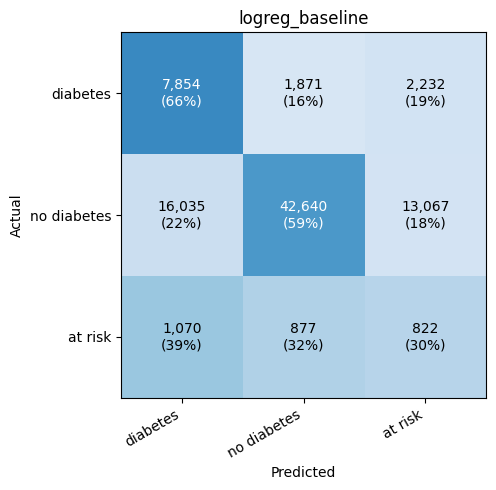

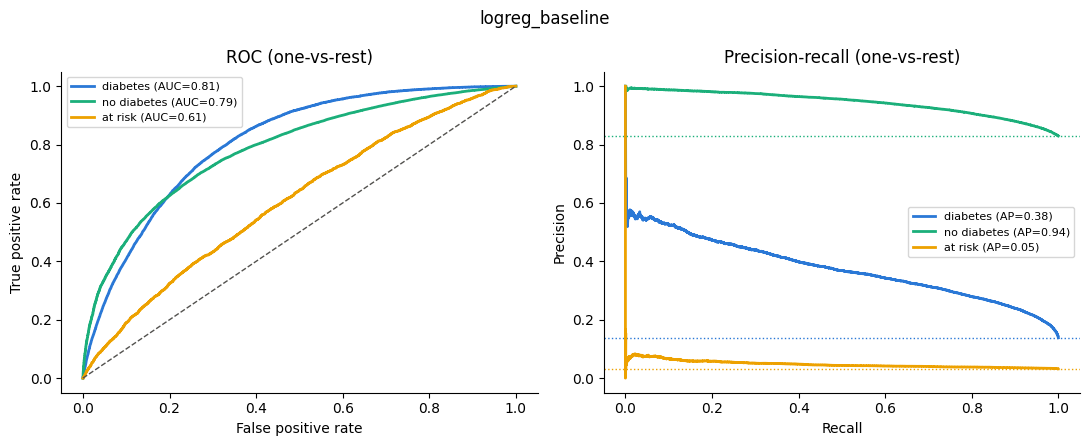

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['bmi', 'age',
                                                   'height_inches', 'weight_kg',
                                                   'poor_physical_health_days',
                                                   'poor_mental_health_days',
                                                   'drinks_per_week',
                                                   'drink_occasions_per_day',
                                                   'exercise_minutes_per_week',
                                                   'vigorous_exercise_minutes_per_...
                                                   'income', 'smoking_status',
                                                   'cholesterol_check',
                                                   'high_cholesterol']),
                                                 ('bin',
                                                  SimpleImputer(strategy='most_frequent'),
                                                  ['high_blood_pressure',
                                                   'stroke', 'heart_disease',
                                                   'kidney_disease',
                                                   'physical_activity',
                                                   'heavy_drinker',
                                                   'health_insurance',
                                                   'cant_afford_doctor',
                                                   'difficulty_walking',
                                                   'sex'])])),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [70]:
baseline_pipeline = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        C=1.0,
        solver="lbfgs",
        random_state=RANDOM_STATE)),
])

config = {"model": "LogisticRegression", "class_weight": "balanced", "C": 1.0,
          "solver": "lbfgs", "max_iter": 1000, "ordinal_encoding": "onehot"}

log_experiment("logreg_baseline", baseline_pipeline, config,
               X_train, Y_train, X_val, Y_val, do_cv=True)


In [71]:
baseline_results = results_log[-1]   # most recent run

screening_summary = pd.DataFrame({
    "metric": [
        "Diabetes: predicted exactly as diabetes (recall)",
        "Diabetes: flagged as diabetes or at risk",
        "Diabetes: missed (predicted no diabetes)",
        "At risk: predicted exactly as at risk (recall)",
        "At risk: flagged as diabetes or at risk",
        "Screening sensitivity (diabetes + at risk combined)",
        "Screening precision (flagged people who truly need follow-up)",
        "Screening specificity (healthy people not flagged)",
        "Screening F2",
        "Screening F1",
        "People flagged (%)",
    ],
    "value": [
        baseline_results["val_recall/diabetes"],
        baseline_results["screen_sensitivity/diabetes"],
        baseline_results["missed/diabetes"],
        baseline_results["val_recall/at risk"],
        baseline_results["screen_sensitivity/at risk"],
        baseline_results["screen_sensitivity"],
        baseline_results["screen_precision"],
        baseline_results["screen_specificity"],
        baseline_results["screen_f2"],
        baseline_results["screen_f1"],
        baseline_results["pct_flagged"],
    ],
})
screening_summary


,metric,value
0,Diabetes: predicted exactly as diabetes (recall),0.6569
1,Diabetes: flagged as diabetes or at risk,0.8435
2,Diabetes: missed (predicted no diabetes),0.1565
3,At risk: predicted exactly as at risk (recall),0.2969
4,At risk: flagged as diabetes or at risk,0.6833
5,Screening sensitivity (diabetes + at risk comb...,0.8134
6,Screening precision (flagged people who truly ...,0.2916
7,Screening specificity (healthy people not flag...,0.5944
8,Screening F2,0.5990
9,Screening F1,0.4293


## Experiment 2: Apply downsampling the majority class, then upsampling the minority class, then reuse the same baseline logistic regression without class weight

[logreg_under_smotenc] SCREENING  sensitivity = 0.597 | precision = 0.361 | F2 = 0.528 | F1 = 0.450 | specificity = 0.783 | flagged = 28.2%
    flagged: diabetes = 0.638 | at risk = 0.420 | diabetics missed = 0.362
    OVERALL  ROC-AUC (OvR) = 0.7248 | macro F1 = 0.4524 | balanced acc = 0.4831 | accuracy = 0.7228
    CV  screening F2 = 0.5299 (+/- 0.0048) | sensitivity = 0.5988 (+/- 0.0062) | precision = 0.3630 (+/- 0.0027) | macro F1 = 0.4555 (+/- 0.0033)
              precision    recall  f1-score   support

    diabetes      0.399     0.486     0.438     11957
 no diabetes      0.904     0.783     0.839     71742
     at risk      0.051     0.180     0.079      2769

    accuracy                          0.723     86468
   macro avg      0.452     0.483     0.452     86468
weighted avg      0.807     0.723     0.760     86468



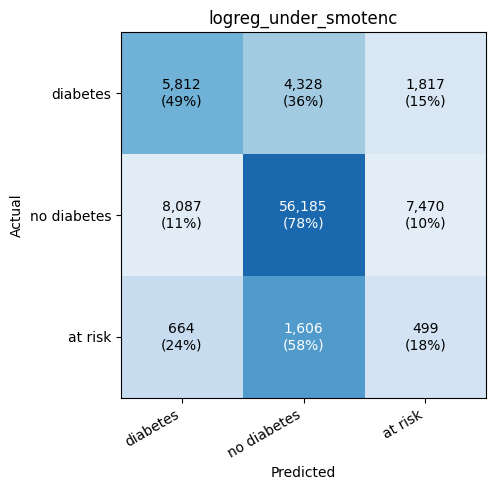

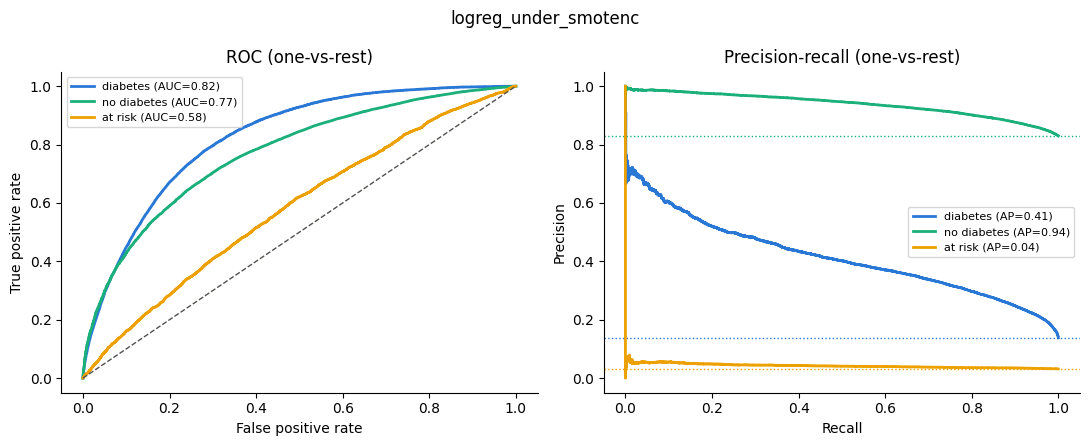

Pipeline(steps=[('impute',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['bmi', 'age',
                                                   'height_inches', 'weight_kg',
                                                   'poor_physical_health_days',
                                                   'poor_mental_health_days',
                                                   'drinks_per_week',
                                                   'drink_occasions_per_day',
                                                   'exercise_minutes_per_week',
                                                   'vigorous_exercise_minutes_per_week',
                                                   'strength_training_per_week']),
                                                 ('cat',
                                                  SimpleImpu...
                                                  ['general_health',
                                                   'age_group', 'education',
                                                   'income', 'smoking_status',
                                                   'cholesterol_check',
                                                   'high_cholesterol']),
                                                 ('bin', 'passthrough',
                                                  ['high_blood_pressure',
                                                   'stroke', 'heart_disease',
                                                   'kidney_disease',
                                                   'physical_activity',
                                                   'heavy_drinker',
                                                   'health_insurance',
                                                   'cant_afford_doctor',
                                                   'difficulty_walking',
                                                   'sex'])])),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))])

In [51]:
from collections import Counter
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTENC


def undersample_no_diabetes(class_labels):
    """Keep 'no diabetes' (3) at 3x the number of diabetes cases."""
    class_counts = Counter(class_labels)
    return {3: min(class_counts[3], 3 * class_counts[1])}


def oversample_minorities(class_labels):
    """Grow diabetes (1) and at risk (4) to half the size of the (undersampled) majority."""
    class_counts = Counter(class_labels)
    target_count = class_counts[3] // 2
    return {1: max(class_counts[1], target_count), 4: max(class_counts[4], target_count)}


# Step 1: impute only (SMOTENC needs the original categories, before one-hot encoding)
impute_step = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", SimpleImputer(strategy="most_frequent"), cat_cols + binary_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

# Step 2: scale and one-hot encode, after resampling
encode_step = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", binary_cols),
])

resampled_pipeline = ImbPipeline([
    ("impute", impute_step),
    ("undersample", RandomUnderSampler(sampling_strategy=undersample_no_diabetes,
                                       random_state=RANDOM_STATE)),
    ("oversample", SMOTENC(categorical_features=cat_cols + binary_cols,
                           sampling_strategy=oversample_minorities,
                           random_state=RANDOM_STATE)),
    ("encode", encode_step),
    ("clf", LogisticRegression(max_iter=1000, C=1.0, solver="lbfgs",
                               random_state=RANDOM_STATE)),   # no class_weight: resampling handles the imbalance
])

resampled_config = {"model": "LogisticRegression", "C": 1.0, "class_weight": "none",
                    "resampling": "undersample 3x + SMOTENC to 1/2"}

log_experiment("logreg_under_smotenc", resampled_pipeline, resampled_config,
               X_train, Y_train, X_val, Y_val, do_cv=True)


## Experiment 3: Oversampling to the majority class only

[logreg_smotenc_1to1] SCREENING  sensitivity = 0.719 | precision = 0.279 | F2 = 0.547 | F1 = 0.402 | specificity = 0.618 | flagged = 43.9%
    flagged: diabetes = 0.751 | at risk = 0.584 | diabetics missed = 0.249
    OVERALL  ROC-AUC (OvR) = 0.7010 | macro F1 = 0.4155 | balanced acc = 0.4893 | accuracy = 0.6011
              precision    recall  f1-score   support

    diabetes      0.353     0.573     0.437     11957
 no diabetes      0.915     0.618     0.738     71742
     at risk      0.041     0.277     0.072      2769

    accuracy                          0.601     86468
   macro avg      0.436     0.489     0.416     86468
weighted avg      0.809     0.601     0.675     86468



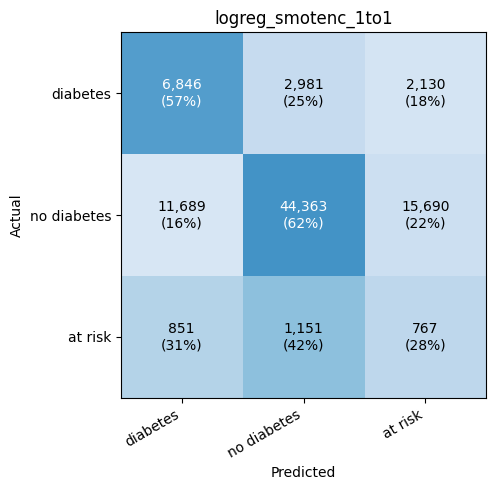

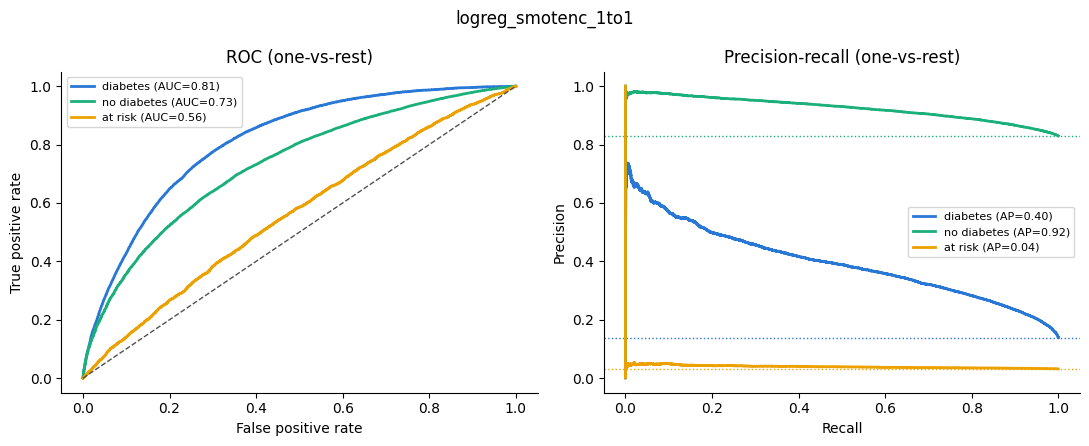

Pipeline(steps=[('impute',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['bmi', 'age',
                                                   'height_inches', 'weight_kg',
                                                   'poor_physical_health_days',
                                                   'poor_mental_health_days',
                                                   'drinks_per_week',
                                                   'drink_occasions_per_day',
                                                   'exercise_minutes_per_week',
                                                   'vigorous_exercise_minutes_per_week',
                                                   'strength_training_per_week']),
                                                 ('cat',
                                                  SimpleImpu...
                                                  ['general_health',
                                                   'age_group', 'education',
                                                   'income', 'smoking_status',
                                                   'cholesterol_check',
                                                   'high_cholesterol']),
                                                 ('bin', 'passthrough',
                                                  ['high_blood_pressure',
                                                   'stroke', 'heart_disease',
                                                   'kidney_disease',
                                                   'physical_activity',
                                                   'heavy_drinker',
                                                   'health_insurance',
                                                   'cant_afford_doctor',
                                                   'difficulty_walking',
                                                   'sex'])])),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))])

In [52]:
from collections import Counter
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC


def oversample_to_majority(class_labels, share_of_majority=1.0):
    """Grow diabetes (1) and at risk (4) to a share of the 'no diabetes' (3) count."""
    class_counts = Counter(class_labels)
    target_count = int(class_counts[3] * share_of_majority)
    return {1: max(class_counts[1], target_count), 4: max(class_counts[4], target_count)}


# Step 1: impute only (SMOTENC needs the original categories, before one-hot encoding)
impute_step = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", SimpleImputer(strategy="most_frequent"), cat_cols + binary_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

# Step 2: scale and one-hot encode, after resampling
encode_step = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", binary_cols),
])

oversample_pipeline = ImbPipeline([
    ("impute", impute_step),
    ("oversample", SMOTENC(categorical_features=cat_cols + binary_cols,
                           sampling_strategy=oversample_to_majority,
                           random_state=RANDOM_STATE)),
    ("encode", encode_step),
    ("clf", LogisticRegression(max_iter=1000, C=1.0, solver="lbfgs",
                               random_state=RANDOM_STATE)),   # no class_weight: resampling handles it
])

oversample_config = {"model": "LogisticRegression", "C": 1.0, "class_weight": "none",
                     "resampling": "SMOTENC to 1:1:1, no undersampling"}

log_experiment("logreg_smotenc_1to1", oversample_pipeline, oversample_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


## Training with Ensemble Model: Random Forest

[rf_depth6_leaf50_estimators_500] SCREENING  sensitivity = 0.818 | precision = 0.301 | F2 = 0.609 | F1 = 0.440 | specificity = 0.609 | flagged = 46.4%
    flagged: diabetes = 0.852 | at risk = 0.676 | diabetics missed = 0.148
    OVERALL  ROC-AUC (OvR) = 0.7459 | macro F1 = 0.4216 | balanced acc = 0.5271 | accuracy = 0.6157
              precision    recall  f1-score   support

    diabetes      0.305     0.745     0.432     11957
 no diabetes      0.942     0.609     0.740     71742
     at risk      0.058     0.227     0.092      2769

    accuracy                          0.616     86468
   macro avg      0.435     0.527     0.422     86468
weighted avg      0.826     0.616     0.677     86468



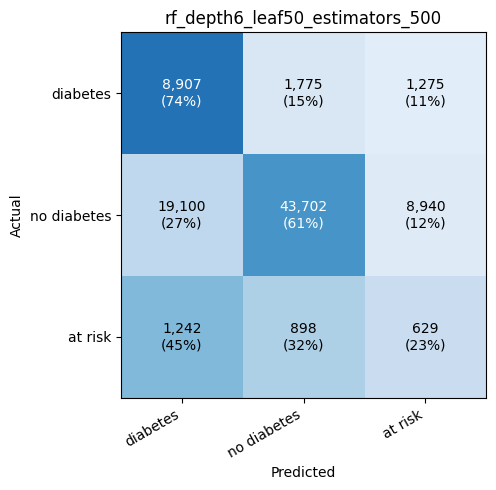

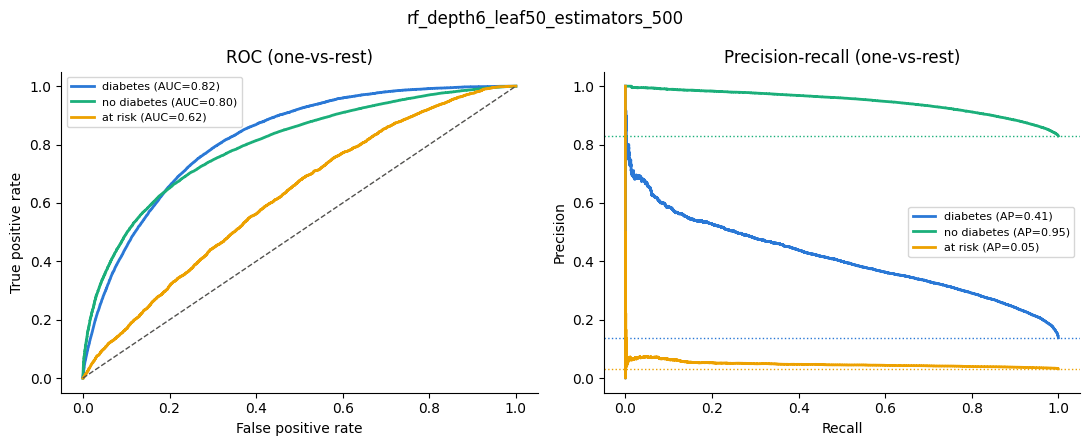

RandomForestClassifier(class_weight='balanced_subsample', max_depth=6,
                       min_samples_leaf=50, n_estimators=500, n_jobs=-1,
                       random_state=42)

In [53]:
forest_model = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced_subsample",
    max_depth=6,
    min_samples_leaf=50,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

forest_config = {"model": "RandomForest", "n_estimators": 500,
                 "class_weight": "balanced_subsample", "max_depth": 6,
                 "min_samples_leaf": 50, "max_features": "sqrt",
                 "missing_values": "native"}

log_experiment("rf_depth6_leaf50_estimators_500", forest_model, forest_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


[rf_depth12_leaf100_estimators_1000] SCREENING  sensitivity = 0.809 | precision = 0.311 | F2 = 0.613 | F1 = 0.449 | specificity = 0.631 | flagged = 44.4%
    flagged: diabetes = 0.844 | at risk = 0.661 | diabetics missed = 0.156
    OVERALL  ROC-AUC (OvR) = 0.7531 | macro F1 = 0.4301 | balanced acc = 0.5306 | accuracy = 0.6340
              precision    recall  f1-score   support

    diabetes      0.311     0.747     0.439     11957
 no diabetes      0.942     0.631     0.756     71742
     at risk      0.061     0.213     0.095      2769

    accuracy                          0.634     86468
   macro avg      0.438     0.531     0.430     86468
weighted avg      0.826     0.634     0.691     86468



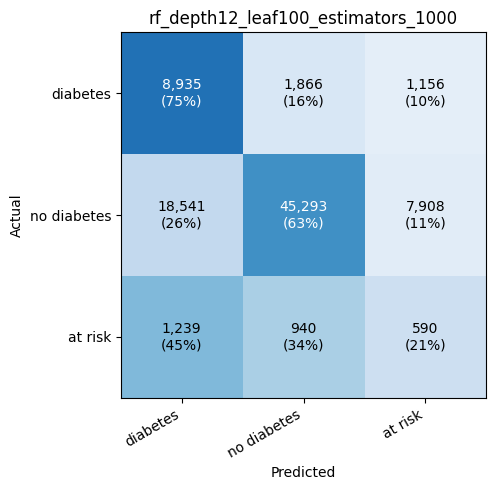

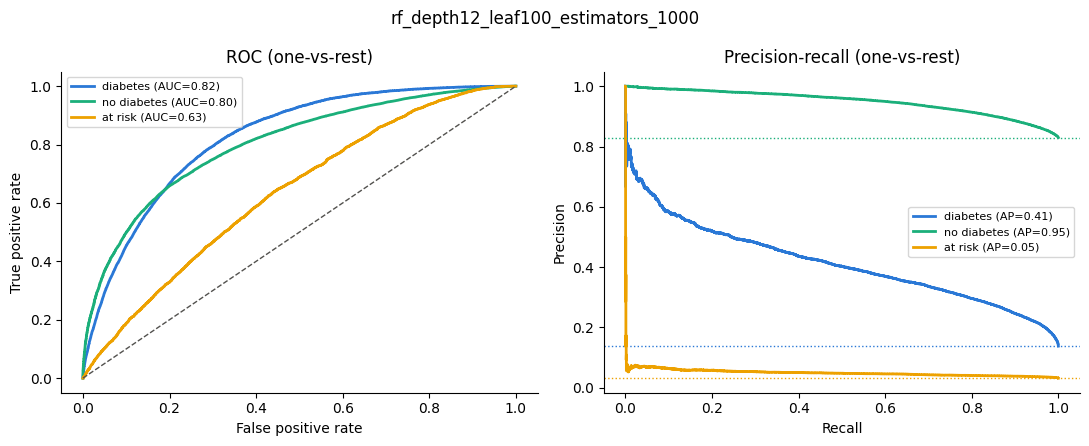

RandomForestClassifier(class_weight='balanced_subsample', max_depth=12,
                       min_samples_leaf=100, n_estimators=1000, n_jobs=-1,
                       random_state=42)

In [54]:
forest_model = RandomForestClassifier(
    n_estimators=1000,
    class_weight="balanced_subsample",
    max_depth=12,
    min_samples_leaf=100,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

forest_config = {"model": "RandomForest", "n_estimators": 1000,
                 "class_weight": "balanced_subsample", "max_depth": 12,
                 "min_samples_leaf": 100, "max_features": "sqrt",
                 "missing_values": "native"}

log_experiment("rf_depth12_leaf100_estimators_1000", forest_model, forest_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


[rf_depth12_leaf100_estimators_2000] SCREENING  sensitivity = 0.810 | precision = 0.311 | F2 = 0.613 | F1 = 0.449 | specificity = 0.631 | flagged = 44.4%
    flagged: diabetes = 0.844 | at risk = 0.661 | diabetics missed = 0.156
    OVERALL  ROC-AUC (OvR) = 0.7532 | macro F1 = 0.4302 | balanced acc = 0.5306 | accuracy = 0.6341
              precision    recall  f1-score   support

    diabetes      0.311     0.748     0.440     11957
 no diabetes      0.942     0.631     0.756     71742
     at risk      0.061     0.212     0.095      2769

    accuracy                          0.634     86468
   macro avg      0.438     0.531     0.430     86468
weighted avg      0.826     0.634     0.691     86468



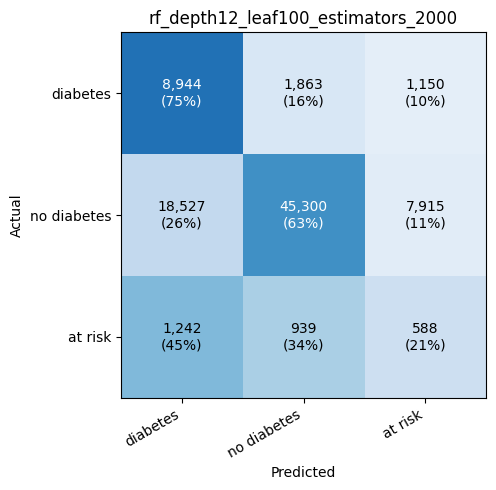

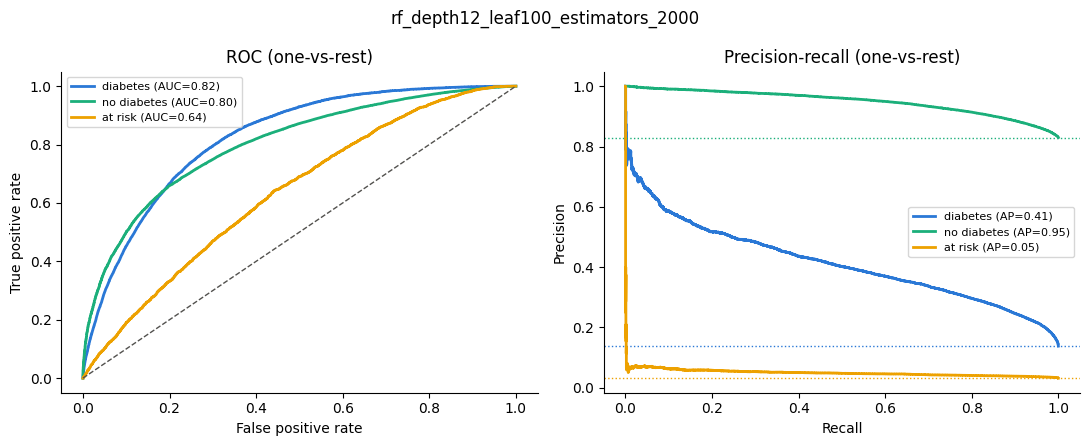

RandomForestClassifier(class_weight='balanced_subsample', max_depth=12,
                       min_samples_leaf=100, n_estimators=2000, n_jobs=-1,
                       random_state=42)

In [55]:
forest_model = RandomForestClassifier(
    n_estimators=2000,
    class_weight="balanced_subsample",
    max_depth=12,
    min_samples_leaf=100,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

forest_config = {"model": "RandomForest", "n_estimators": 2000,
                 "class_weight": "balanced_subsample", "max_depth": 12,
                 "min_samples_leaf": 100, "max_features": "sqrt",
                 "missing_values": "native"}

log_experiment("rf_depth12_leaf100_estimators_2000", forest_model, forest_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


[rf_depth18_leaf200_estimators_2000] SCREENING  sensitivity = 0.816 | precision = 0.306 | F2 = 0.612 | F1 = 0.445 | specificity = 0.620 | flagged = 45.5%
    flagged: diabetes = 0.849 | at risk = 0.674 | diabetics missed = 0.151
    OVERALL  ROC-AUC (OvR) = 0.7519 | macro F1 = 0.4275 | balanced acc = 0.5320 | accuracy = 0.6240
              precision    recall  f1-score   support

    diabetes      0.313     0.740     0.440     11957
 no diabetes      0.943     0.620     0.748     71742
     at risk      0.059     0.237     0.095      2769

    accuracy                          0.624     86468
   macro avg      0.438     0.532     0.427     86468
weighted avg      0.827     0.624     0.684     86468



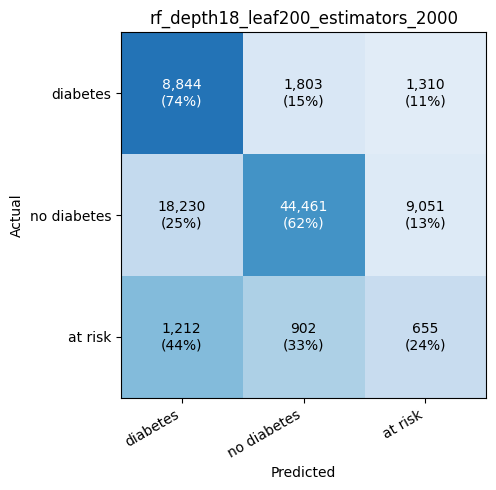

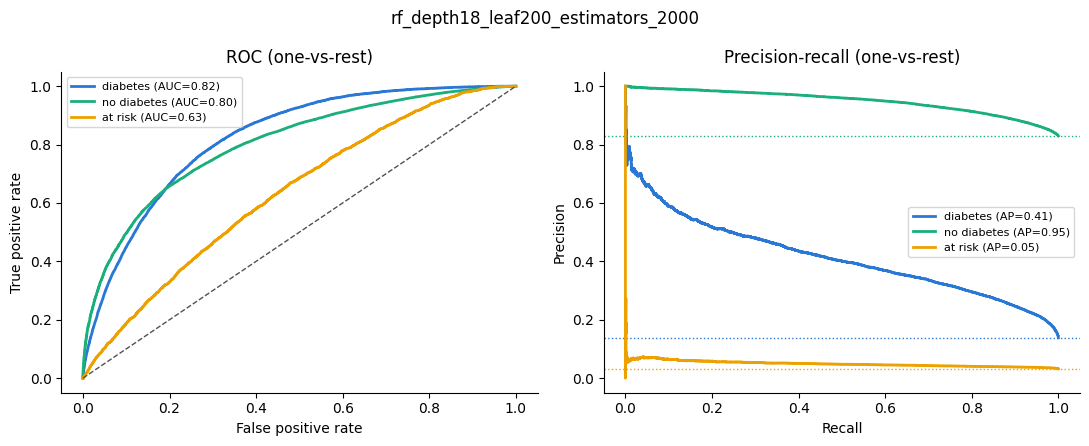

RandomForestClassifier(class_weight='balanced_subsample', max_depth=18,
                       min_samples_leaf=200, n_estimators=2000, n_jobs=-1,
                       random_state=42)

In [56]:
forest_model = RandomForestClassifier(
    n_estimators=2000,
    class_weight="balanced_subsample",
    max_depth=18,
    min_samples_leaf=200,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

forest_config = {"model": "RandomForest", "n_estimators": 2000,
                 "class_weight": "balanced_subsample", "max_depth": 18,
                 "min_samples_leaf": 200, "max_features": "sqrt",
                 "missing_values": "native"}

log_experiment("rf_depth18_leaf200_estimators_2000", forest_model, forest_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


## Notice
Across the random forest variants tested so far, none outperformed the logistic regression baseline on screening F2 (best = 0.61 for both). Since random forests can capture non-linear effects and interactions between features, this suggests that the relationship between the survey answers and diabetes status is largely additive, a pattern a linear model already captures well. It also suggests that several features add little information beyond others (for example, age_group repeats age, and bmi combines height_inches and weight_kg).

To quantify each feature's contribution, we run permutation importance on the baseline logistic regression model: each feature is shuffled in turn, and the resulting drop in screening F2 on the validation set measures how much the model relies on it.


In [57]:
fitted_baseline = baseline_pipeline   # already fitted by log_experiment

importance_result = permutation_importance(
    fitted_baseline, X_val, Y_val,
    scoring=make_scorer(screen_f2),
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

feature_importance = pd.DataFrame({
    "feature": X_val.columns,
    "f2_drop_mean": importance_result.importances_mean,
    "f2_drop_std": importance_result.importances_std,
}).sort_values("f2_drop_mean", ascending=False)

feature_importance


,feature,f2_drop_mean,f2_drop_std
5,age,0.039477,0.001066
11,general_health,0.032025,0.002015
17,high_blood_pressure,0.021206,0.001304
18,high_cholesterol,0.017490,0.001155
0,bmi,0.008867,0.000560
4,drink_occasions_per_day,0.008171,0.000630
16,cholesterol_check,0.007770,0.000714
7,weight_kg,0.005991,0.000605
12,age_group,0.005409,0.001131
20,heart_disease,0.002317,0.000333


Attempt training baseline with 13 features

[logreg_13_features] SCREENING  sensitivity = 0.810 | precision = 0.305 | F2 = 0.609 | F1 = 0.443 | specificity = 0.621 | flagged = 45.3%
    flagged: diabetes = 0.846 | at risk = 0.658 | diabetics missed = 0.154
    OVERALL  ROC-AUC (OvR) = 0.7396 | macro F1 = 0.4252 | balanced acc = 0.5224 | accuracy = 0.6147
              precision    recall  f1-score   support

    diabetes      0.330     0.651     0.438     11957
 no diabetes      0.941     0.621     0.748     71742
     at risk      0.053     0.295     0.089      2769

    accuracy                          0.615     86468
   macro avg      0.441     0.522     0.425     86468
weighted avg      0.828     0.615     0.684     86468



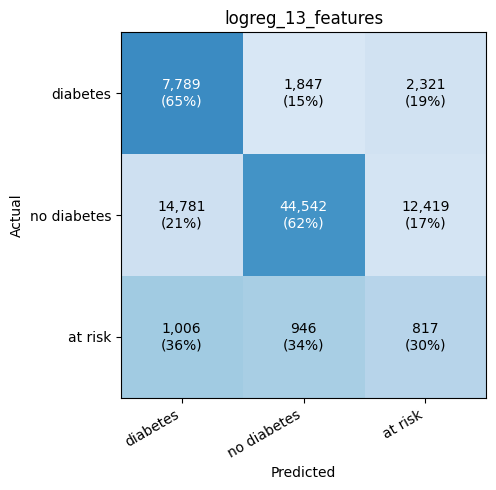

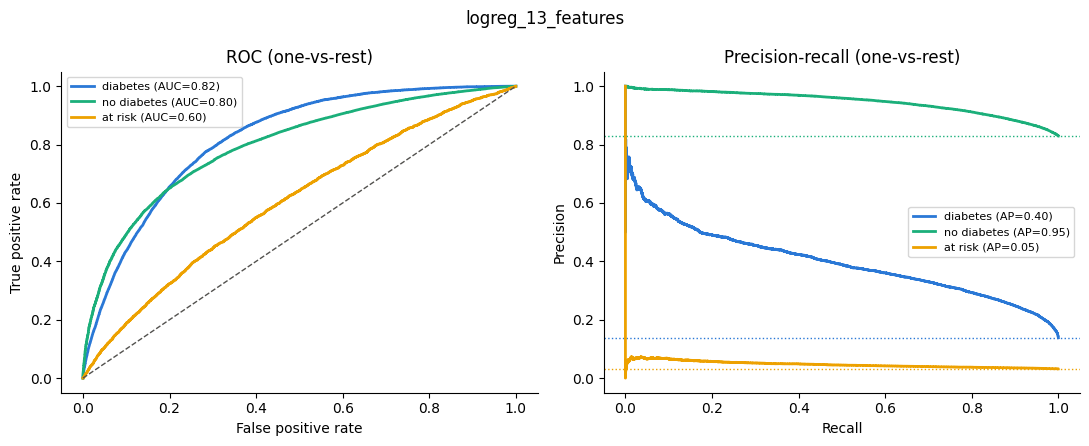

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['bmi', 'age', 'weight_kg',
                                                   'drink_occasions_per_day']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('ohe',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['general_health',
                                                   'education', 'income',
                                                   'cholesterol_check',
                                                   'high_cholesterol']),
                                                 ('bin',
                                                  SimpleImputer(strategy='most_frequent'),
                                                  ['high_blood_pressure',
                                                   'heart_disease',
                                                   'kidney_disease',
                                                   'difficulty_walking'])])),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [58]:
selected_features = [
    # numeric
    "age", "bmi", "weight_kg", "drink_occasions_per_day",
    # ordinal / categorical
    "general_health", "cholesterol_check", "high_cholesterol", "education", "income",
    # binary
    "high_blood_pressure", "heart_disease", "kidney_disease", "difficulty_walking",
]

selected_numeric_cols = [column for column in numeric_cols if column in selected_features]
selected_cat_cols = [column for column in cat_cols if column in selected_features]
selected_binary_cols = [column for column in binary_cols if column in selected_features]

selected_preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), selected_numeric_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore")),
    ]), selected_cat_cols),
    ("bin", SimpleImputer(strategy="most_frequent"), selected_binary_cols),
])

selected_pipeline = Pipeline([
    ("prep", selected_preprocess),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", C=1.0,
                               solver="lbfgs", random_state=RANDOM_STATE)),
])

selected_config = {"model": "LogisticRegression", "class_weight": "balanced", "C": 1.0,
                   "n_features": len(selected_features), "features": "top-13 by permutation F2"}

log_experiment("logreg_13_features", selected_pipeline, selected_config,
               X_train[selected_features], Y_train, X_val[selected_features], Y_val, do_cv=False)


[lgbm_baseline] SCREENING  sensitivity = 0.796 | precision = 0.319 | F2 = 0.613 | F1 = 0.455 | specificity = 0.651 | flagged = 42.5%
    flagged: diabetes = 0.831 | at risk = 0.643 | diabetics missed = 0.169
    OVERALL  ROC-AUC (OvR) = 0.7518 | macro F1 = 0.4358 | balanced acc = 0.5285 | accuracy = 0.6466
              precision    recall  f1-score   support

    diabetes      0.324     0.719     0.446     11957
 no diabetes      0.940     0.651     0.769     71742
     at risk      0.058     0.215     0.092      2769

    accuracy                          0.647     86468
   macro avg      0.441     0.528     0.436     86468
weighted avg      0.826     0.647     0.703     86468



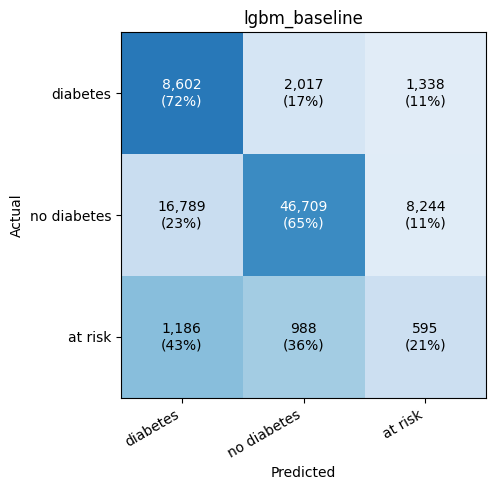

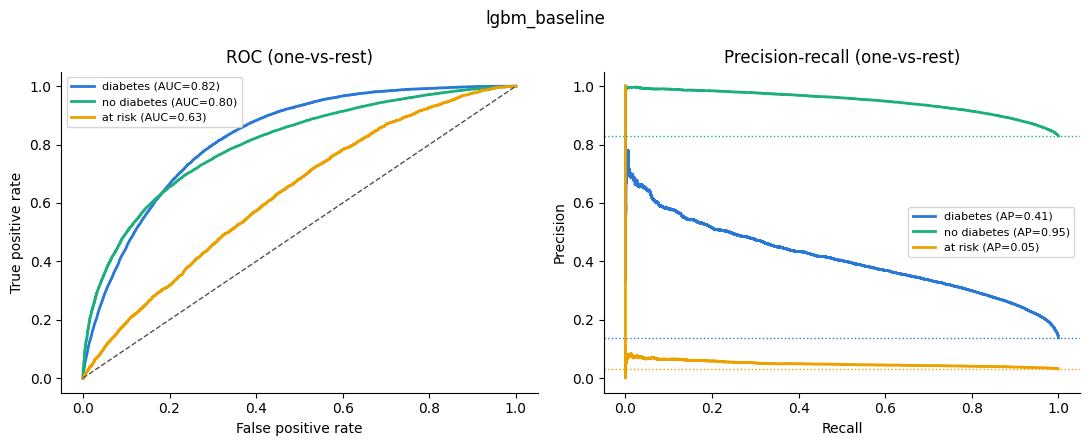

LGBMClassifier(class_weight='balanced', colsample_bytree=0.8,
               learning_rate=0.05, min_child_samples=50, n_estimators=1000,
               n_jobs=-1, random_state=42, subsample=0.8, subsample_freq=1,
               verbose=-1)

In [73]:
from lightgbm import LGBMClassifier

lightgbm_model = LGBMClassifier(
    class_weight="balanced",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=50,      # like min_samples_leaf in the forest: lets the class weights work
    subsample=0.8,             # each tree sees 80% of the rows...
    subsample_freq=1,          # ...re-drawn for every tree
    colsample_bytree=0.8,      # each tree sees 80% of the features
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,                # hide LightGBM's training messages
)

lightgbm_config = {"model": "LightGBM", "class_weight": "balanced", "n_estimators": 1000,
                   "learning_rate": 0.05, "num_leaves": 31, "min_child_samples": 50,
                   "subsample": 0.8, "colsample_bytree": 0.8, "categorical": "ordinal as numbers"}

log_experiment("lgbm_baseline", lightgbm_model, lightgbm_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


In [78]:
fitted_lightgbm = lightgbm_model   # already fitted by log_experiment

lightgbm_importance_result = permutation_importance(
    fitted_lightgbm, X_val, Y_val,
    scoring=make_scorer(screen_f2),
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

lightgbm_feature_importance = pd.DataFrame({
    "feature": X_val.columns,
    "f2_drop_mean": lightgbm_importance_result.importances_mean,
    "f2_drop_std": lightgbm_importance_result.importances_std,
}).sort_values("f2_drop_mean", ascending=False)

lightgbm_feature_importance


,feature,f2_drop_mean,f2_drop_std
11,general_health,0.029689,0.001398
5,age,0.024786,0.002074
17,high_blood_pressure,0.019531,0.001276
18,high_cholesterol,0.015668,0.001386
0,bmi,0.012742,0.000975
12,age_group,0.012162,0.000482
4,drink_occasions_per_day,0.010382,0.001030
16,cholesterol_check,0.007983,0.000935
3,drinks_per_week,0.005946,0.000881
7,weight_kg,0.004923,0.001107


[lgbm_18_clinical_original] SCREENING  sensitivity = 0.803 | precision = 0.310 | F2 = 0.609 | F1 = 0.447 | specificity = 0.633 | flagged = 44.1%
    flagged: diabetes = 0.839 | at risk = 0.648 | diabetics missed = 0.161
    OVERALL  ROC-AUC (OvR) = 0.7486 | macro F1 = 0.4298 | balanced acc = 0.5259 | accuracy = 0.6314
              precision    recall  f1-score   support

    diabetes      0.323     0.714     0.445     11957
 no diabetes      0.940     0.633     0.757     71742
     at risk      0.055     0.231     0.088      2769

    accuracy                          0.631     86468
   macro avg      0.439     0.526     0.430     86468
weighted avg      0.826     0.631     0.692     86468



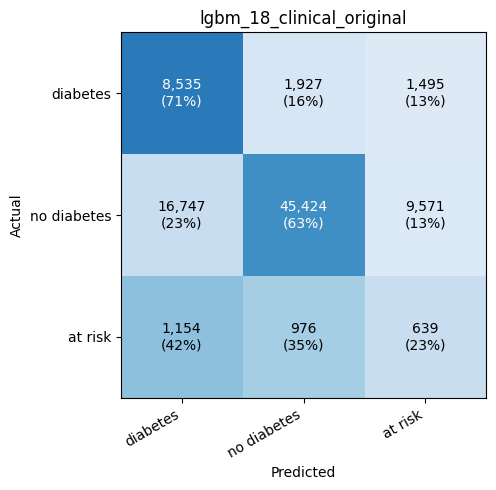

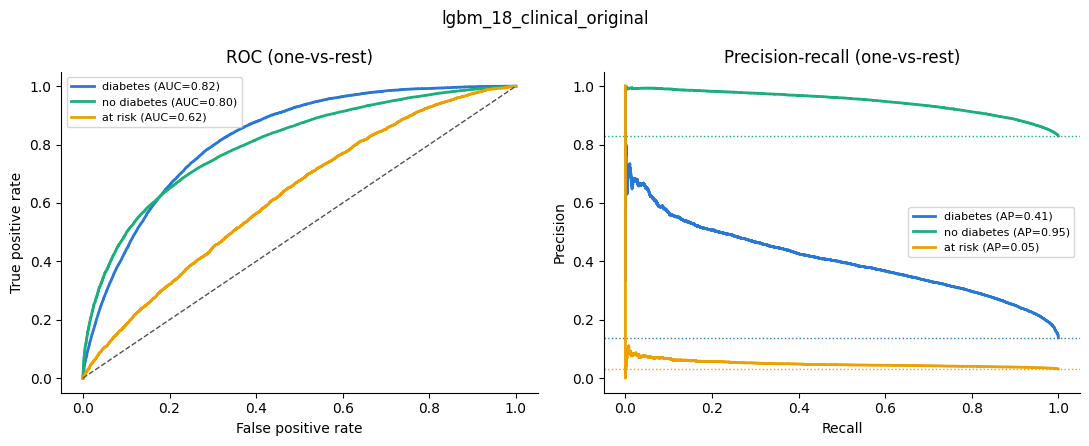

LGBMClassifier(class_weight='balanced', colsample_bytree=0.8,
               learning_rate=0.05, min_child_samples=50, n_estimators=1000,
               n_jobs=-1, random_state=42, subsample=0.8, subsample_freq=1,
               verbose=-1)

In [84]:
# train with selected value
selected_features = [
    # numeric
    "age", "bmi", "weight_kg", "drink_occasions_per_day", "drinks_per_week",
    "exercise_minutes_per_week",
    # ordinal / categorical
    "general_health", "high_cholesterol", "cholesterol_check", "smoking_status",
    # binary
    "high_blood_pressure", "sex", "kidney_disease", "heart_disease",
    "difficulty_walking", "physical_activity", "stroke", "heavy_drinker", 
]

lightgbm_model = LGBMClassifier(
    class_weight="balanced",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=50,      # like min_samples_leaf in the forest: lets the class weights work
    subsample=0.8,             # each tree sees 80% of the rows...
    subsample_freq=1,          # ...re-drawn for every tree
    colsample_bytree=0.8,      # each tree sees 80% of the features
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,                # hide LightGBM's training messages
)

lightgbm_config = {"model": "LightGBM", "class_weight": "balanced", "n_estimators": 1000,
                   "learning_rate": 0.05, "num_leaves": 31, "min_child_samples": 50,
                   "subsample": 0.8, "colsample_bytree": 0.8, "categorical": "ordinal as numbers"}

lightgbm_reduced_config = {**lightgbm_config, "n_features": len(selected_features),
                           "features": "18: permutation F2 + clinical risk factors"}

log_experiment("lgbm_18_clinical_original", lightgbm_model, lightgbm_reduced_config,
               X_train[selected_features], Y_train, X_val[selected_features], Y_val, do_cv=False)


[logreg_splines_age_bmi] SCREENING  sensitivity = 0.812 | precision = 0.291 | F2 = 0.598 | F1 = 0.428 | specificity = 0.594 | flagged = 47.5%
    flagged: diabetes = 0.842 | at risk = 0.683 | diabetics missed = 0.158
    OVERALL  ROC-AUC (OvR) = 0.7340 | macro F1 = 0.4131 | balanced acc = 0.5149 | accuracy = 0.5927
              precision    recall  f1-score   support

    diabetes      0.315     0.654     0.426     11957
 no diabetes      0.939     0.594     0.728     71742
     at risk      0.050     0.296     0.086      2769

    accuracy                          0.593     86468
   macro avg      0.435     0.515     0.413     86468
weighted avg      0.824     0.593     0.665     86468



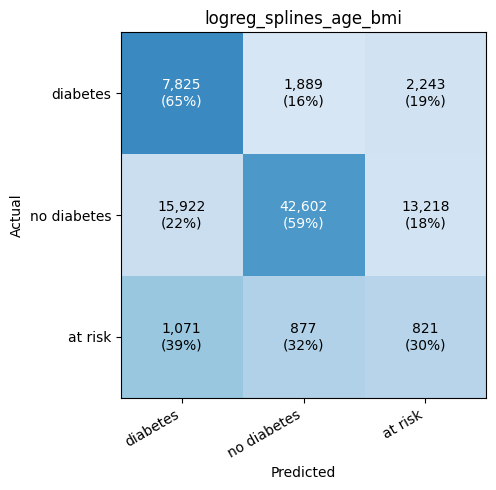

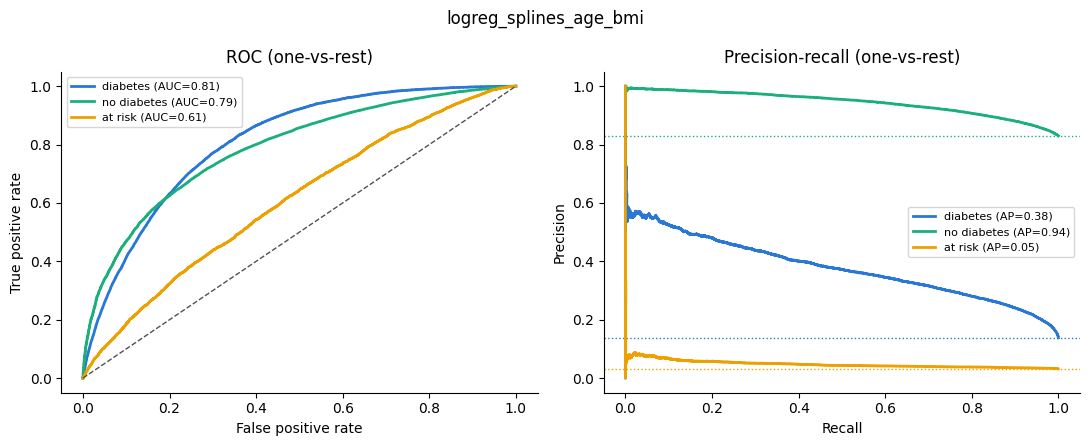

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('spline',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('spline',
                                                                   SplineTransformer())]),
                                                  ['age', 'bmi']),
                                                 ('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['height_inches', 'weight_kg',
                                                   'poor_physical_health_days',
                                                   'poor_mental_health_day...
                                                   'income', 'smoking_status',
                                                   'cholesterol_check',
                                                   'high_cholesterol']),
                                                 ('bin',
                                                  SimpleImputer(strategy='most_frequent'),
                                                  ['high_blood_pressure',
                                                   'stroke', 'heart_disease',
                                                   'kidney_disease',
                                                   'physical_activity',
                                                   'heavy_drinker',
                                                   'health_insurance',
                                                   'cant_afford_doctor',
                                                   'difficulty_walking',
                                                   'sex'])])),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [86]:
from sklearn.preprocessing import SplineTransformer

spline_cols = ["age", "bmi"]
other_numeric_cols = [column for column in numeric_cols if column not in spline_cols]

spline_preprocess = ColumnTransformer([
    ("spline", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("spline", SplineTransformer(n_knots=5, degree=3)),
    ]), spline_cols),
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), other_numeric_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
    ("bin", SimpleImputer(strategy="most_frequent"), binary_cols),
])

spline_pipeline = Pipeline([
    ("prep", spline_preprocess),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", C=1.0,
                               solver="lbfgs", random_state=RANDOM_STATE)),
])

spline_config = {"model": "LogisticRegression", "class_weight": "balanced", "C": 1.0,
                 "splines": "age, bmi (5 knots, cubic)"}

log_experiment("logreg_splines_age_bmi", spline_pipeline, spline_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


In [87]:
comparison_columns = [
    "run_name",
    "screen_f2", "screen_f1", "screen_sensitivity", "screen_precision", "screen_specificity",
    "screen_sensitivity/diabetes", "screen_sensitivity/at risk", "missed/diabetes", "pct_flagged",
    "val_recall/diabetes", "val_recall/at risk", "val_precision/diabetes", "val_precision/at risk",
    "val_pr_auc/diabetes", "val_pr_auc/at risk", "val_roc_auc_ovr", "val_f1_macro",
]
results_table = pd.DataFrame(results_log)
results_table[[column for column in comparison_columns if column in results_table.columns]] \
    .sort_values("screen_f2", ascending=False)


,run_name,screen_f2,screen_f1,screen_sensitivity,screen_precision,screen_specificity,screen_sensitivity/diabetes,screen_sensitivity/at risk,missed/diabetes,pct_flagged,val_recall/diabetes,val_recall/at risk,val_precision/diabetes,val_precision/at risk,val_pr_auc/diabetes,val_pr_auc/at risk,val_roc_auc_ovr,val_f1_macro
1,lgbm_baseline,0.6127,0.4554,0.7959,0.3189,0.6511,0.8313,0.6432,0.1687,42.5059,0.7194,0.2149,0.3237,0.0585,0.4099,0.0491,0.7518,0.4358
2,lgbm_baseline,0.6127,0.4554,0.7959,0.3189,0.6511,0.8313,0.6432,0.1687,42.5059,0.7194,0.2149,0.3237,0.0585,0.4099,0.0491,0.7518,0.4358
3,lgbm_18_clinical,0.6092,0.4473,0.8029,0.3100,0.6332,0.8388,0.6475,0.1612,44.1100,0.7138,0.2308,0.3229,0.0546,0.4052,0.0489,0.7486,0.4298
6,lgbm_18_clinical_original,0.6092,0.4473,0.8029,0.3100,0.6332,0.8388,0.6475,0.1612,44.1100,0.7138,0.2308,0.3229,0.0546,0.4052,0.0489,0.7486,0.4298
4,lgbm_18_clinical,0.6049,0.4558,0.7737,0.3231,0.6672,0.8146,0.5973,0.1854,40.7897,0.7097,0.1762,0.3231,0.0542,0.4017,0.0473,0.7445,0.4352
0,logreg_baseline,0.5990,0.4293,0.8134,0.2916,0.5944,0.8435,0.6833,0.1565,47.5089,0.6569,0.2969,0.3147,0.0510,0.3755,0.0477,0.7332,0.4135
7,logreg_splines_age_bmi,0.5980,0.4285,0.8122,0.2910,0.5938,0.8420,0.6833,0.1580,47.5320,0.6544,0.2965,0.3153,0.0504,0.3774,0.0480,0.7340,0.4131
5,lgbm_18_clinical_0.08,0.5964,0.4596,0.7440,0.3325,0.6934,0.7865,0.5605,0.2135,38.1077,0.6942,0.1492,0.3235,0.0566,0.3963,0.0456,0.7388,0.4393


###### %load_ext tensorboard
%tensorboard --logdir {LOG_DIR}

Citations:
1. Vounzoulaki E, Khunti K, Abner SC, Tan BK, Davies MJ, Gillies CL. Progression to type 2 diabetes in women with a known history of gestational diabetes: systematic review and meta-analysis. BMJ. 2020;369:m1361.
https://www.bmj.com/content/bmj/369/bmj.m1361.full.pdf